![PIC UPV PERTE Chip Chair Logo](https://www.pic-chair.upv.es/wp-content/uploads/2024/05/logo-upv-horizontal.png)
![PIC UPV PERTE Chip Chair Logo](https://www.pic-chair.upv.es/wp-content/uploads/2024/06/logos-perte-chip-1024x119.png)


# Laboratory 3. Interferometers I - MZI


Today we will work on the design and modeling of an **Mach-Zenhder Interferometer (MZI)** used in integrated photonic circuits. We will perform simulations that will allow us to understand how it operates.


## 0.1 General libraries

In [1]:
import gdsfactory as gf # If we deal with a MZ in a PDK, we will have tu use this
import jax # Mathematical tools, like the parent version of sax
import jax.example_libraries.optimizers as opt
import jax.numpy as jnp
import matplotlib.pyplot as plt
from matplotlib.pyplot import cm

import numpy as np
import sax
from gdsfactory.generic_tech import get_generic_pdk
from scipy import constants
from scipy.constants import c
from scipy.interpolate import interp1d

import gplugins.sax as gs
from gplugins.common.config import PATH

C:\Users\cfp\AppData\Local\Temp\ipykernel_13984\49810635.py:10: DeprecationWarning: The 'gdsfactory.generic_tech' module is deprecated and will be removed in a future version. Please update your imports to use 'gdsfactory.gpdk' instead:
  from gdsfactory.gpdk import LAYER, LAYER_STACK, get_generic_pdk
Or for submodules:
  from gdsfactory.gpdk.layer_map import LAYER
  from gdsfactory.gpdk.layer_stack import LAYER_STACK
  from gdsfactory.generic_tech import get_generic_pdk


## 1. MZI modeling
Let's compute the transfer function of a MZI

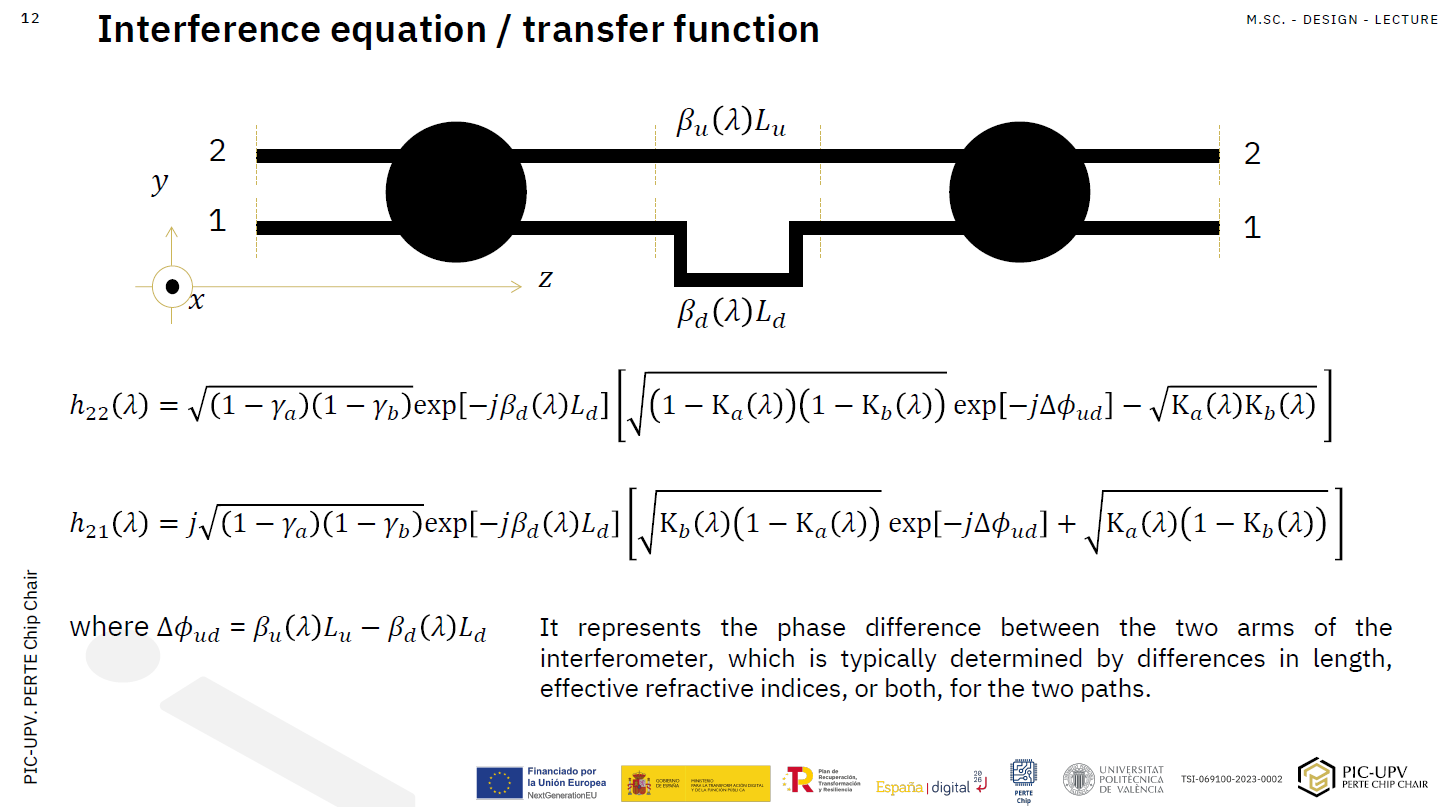

In [7]:
### Waveguides configuration ###

## Propagation parameters

## SOI cross-section ##
SOI = np.loadtxt('SOI-w450-h220-clad600.txt', skiprows=1, delimiter='\t')

wvl = SOI[:, 0]
neffu = SOI[:, 3] #balanced configuration // (neff TE mode) upper arm
neffd = SOI[:, 3] #balanced configuration // (neff TE mode) under arm

## SiN cross-section ##
# SiN_clad = np.loadtxt('SiN-h300nm-w1000nm-Cladding.txt', skiprows=1, delimiter='\t')
# SiN_wat = np.loadtxt('SiN-h300nm-w1000nm-Water.txt', skiprows=1, delimiter='\t')

# wvl0 = SiN_clad[:, 0]
# neffu0 = SiN_clad[:, 3] #balanced configuration // (neff TE mode)
# neffd0 = SiN_wat[:, 3] #balanced configuration // (neff TE mode)

# interp_neffu = interp1d(wvl0, neffu0, kind='cubic')  # Cubic interpolation for smoothness
# interp_neffd = interp1d(wvl0, neffd0, kind='cubic')
# wvl = np.linspace(wvl0.min(), wvl0.max(), 1000)
# neffu = interp_neffu(wvl)
# neffd = interp_neffd(wvl)
def mathematical_MZ(wvl, alphau, alphad, Lu, Ld,
                    neffu, neffd,
                    gamma_a, gamma_b,
                    K_a, K_b ,
                    title = 'MZI Transfer function',
                    nm = False):
    # Propagation lossof each arm
    #alphau = 0 #losless case [dB/um]
    #alphad = 0; #losless case [dB/um]
    alphau_np = (jnp.log(10.0)/10.0) * alphau   # neper/um
    alphad_np = (jnp.log(10.0)/10.0) * alphad   # neper/um

    # Path length
    #Lu = 25; # um
    #Ld = 5; # um

    betau = (2*jnp.pi/wvl)*neffu-1j*alphau_np/2
    betad = (2*jnp.pi/wvl)*neffd-1j*alphad_np/2

    Delta_phi_ud = betau*Lu - betad*Ld

    ### Couplers configuration ###
    # Excess loss
    gamma_a = gamma_a; #null excess loss
    gamma_b = gamma_b; #null excess loss

    # Coupling constant
    K_a = K_a
    K_b = K_b

    # MZI transfer function (h22 & h21)

    #  h_22(wvl)
    h_22 = (np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*(( np.sqrt((1 - K_a) * (1 - K_b)) * np.exp(-1j * Delta_phi_ud))-(np.sqrt(K_a * K_b)))

    #  h_21(wvl)
    h_21 = (1j * np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*((np.sqrt(K_b * (1 - K_a)) * np.exp(-1j * Delta_phi_ud))+(np.sqrt(K_a * (1 - K_b))))

    H21 = np.abs(h_21) ** 2
    H22 = np.abs(h_22) ** 2

    # Plot
    if nm == True:
        wvl = wvl*1000
        plt.xlabel(r'$\lambda (nm)$')
    else: 
        plt.xlabel(r'$\lambda (\mu m)$')
    color = cm.rainbow(np.linspace(0, 1, 10))
    plt.plot(wvl, H22, linestyle='-', color=color[1], label='H22')
    plt.plot(wvl, H21, linestyle='--', color=color[1], label='H21')
    plt.ylabel(r'$|h|^2$')
    plt.title(title)
    plt.legend()
    plt.grid(True)

    plt.show()
    return H22, H21

In [29]:
from scipy.signal import find_peaks
from scipy.interpolate import interp1d


def _refine_extrema(wvl, y, indices):
    """Sub-grid 3-point parabolic refinement around detected extrema to avoid a quantization of FSR, due to lambda step"""
    refined_wvl, refined_val = [], []
    for idx in indices:
        if 0 < idx < len(wvl) - 1:
            dx = wvl[idx - 1 : idx + 2] - wvl[idx]
            y_seg = y[idx - 1 : idx + 2]
            a, b, c = np.polyfit(dx, y_seg, 2)
            if a != 0:
                dx_v = -b / (2.0 * a)
                if dx[0] <= dx_v <= dx[2]:
                    refined_wvl.append(wvl[idx] + dx_v)
                    refined_val.append(a * dx_v**2 + b * dx_v + c)
                    continue
        refined_wvl.append(wvl[idx])
        refined_val.append(y[idx])
    return np.array(refined_wvl), np.array(refined_val)


def analyze_mzi_channel(wvl, H, prominence_ratio=0.1):
    """Extract max/min amplitudes and FSR from a single MZI transfer function."""
    order = np.argsort(wvl)
    wvl = np.asarray(wvl)[order]
    H = np.asarray(H)[order]

    span = np.ptp(H)
    if span > 1e-9:
        prom = prominence_ratio * span
        peak_idx, _ = find_peaks(H, prominence=prom)
        trough_idx, _ = find_peaks(-H, prominence=prom)
    else:
        peak_idx = np.array([], dtype=int)
        trough_idx = np.array([], dtype=int)

    peak_wvl, peak_amp = _refine_extrema(wvl, H, peak_idx)
    trough_wvl, trough_amp = _refine_extrema(wvl, H, trough_idx)

    fsr_peaks = np.diff(peak_wvl) if len(peak_wvl) >= 2 else np.array([])
    fsr_troughs = np.diff(trough_wvl) if len(trough_wvl) >= 2 else np.array([])

    # Combine peak-to-peak and trough-to-trough spacings for the average FSR
    all_fsr = np.concatenate([fsr_peaks, fsr_troughs])
    fsr_mean = float(np.mean(all_fsr)) if len(all_fsr) > 0 else np.nan

    return {
        "max_amp": float(np.max(H)),
        "min_amp": float(np.min(H)),
        "peak_wvl": peak_wvl,
        "peak_amp": peak_amp,
        "trough_wvl": trough_wvl,
        "trough_amp": trough_amp,
        "fsr_peaks": fsr_peaks,
        "fsr_troughs": fsr_troughs,
        "fsr_mean": fsr_mean,
    }


def evaluate_mzi(
    wvl, alphau, alphad, Lu, Ld,
    neffu, neffd,
    gamma_a, gamma_b,
    K_a, K_b,
    title="MZI Transfer function",
    nm=False,
    plot_extrema=True,
):
    """Run mathematical_MZ and extract amplitude bounds and FSR for H22 and H21."""
    H22, H21 = mathematical_MZ(
        wvl, alphau, alphad, Lu, Ld,
        neffu, neffd,
        gamma_a, gamma_b,
        K_a, K_b,
        title=title,
        nm=nm,
    )

    wvl_unit = wvl * 1000.0 if nm else wvl
    unit_str = "nm" if nm else "um"

    res_H22 = analyze_mzi_channel(wvl_unit, H22)
    res_H21 = analyze_mzi_channel(wvl_unit, H21)

    for name, res in [("H22", res_H22), ("H21", res_H21)]:
        print(f"--- {name} ---")
        print(f"  Max amplitude : {res['max_amp']:.6f}")
        print(f"  Min amplitude : {res['min_amp']:.6f}")
        print(f"  Mean FSR      : {res['fsr_mean']:.6f} {unit_str}")
        print(f"Extintion ratio : {((res['max_amp']-res['min_amp'])/res['max_amp'])*100}")
        if len(res["fsr_peaks"]) > 0:
            print(f"  FSR (peaks)   : {np.round(res['fsr_peaks'], 6)} {unit_str}")
        if len(res["fsr_troughs"]) > 0:
            print(f"  FSR (troughs) : {np.round(res['fsr_troughs'], 6)} {unit_str}")

    if plot_extrema:
        fig, ax = plt.subplots(figsize=(8, 4.5))
        ax.plot(wvl_unit, H22, "-", label="H22")
        ax.plot(wvl_unit, H21, "--", label="H21")
        ax.plot(res_H22["peak_wvl"], res_H22["peak_amp"], "^", color="C0", label="H22 max")
        ax.plot(res_H22["trough_wvl"], res_H22["trough_amp"], "v", color="C0", label="H22 min")
        ax.plot(res_H21["peak_wvl"], res_H21["peak_amp"], "^", color="C1", label="H21 max")
        ax.plot(res_H21["trough_wvl"], res_H21["trough_amp"], "v", color="C1", label="H21 min")
        ax.set_xlabel(rf"$\lambda\ ({unit_str})$")
        ax.set_ylabel(r"$|h|^2$")
        ax.set_title(f"{title} — Detected Extrema")
        ax.grid(True)
        ax.legend(ncol=2)
        plt.tight_layout()
        plt.show()

    return H22, H21, res_H22, res_H21

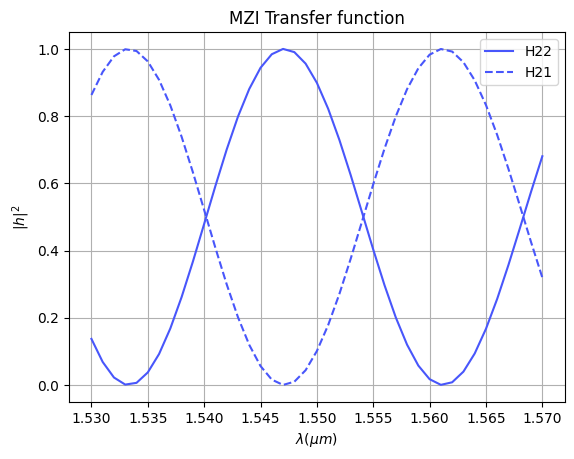

In [30]:
## SOI cross-section ##
SOI = np.loadtxt('SOI-w450-h220-clad600.txt', skiprows=1, delimiter='\t')

wvl = SOI[:, 0]
neffu = SOI[:, 3] #balanced configuration // (neff TE mode) upper arm
neffd = SOI[:, 3] #balanced configuration // (neff TE mode) under arm

# Parameters arms
alphau = 0
Lu = 25
alphad = 0
Ld = 5

# Parameters couplers
gamma_a = 0
gamma_b = 0
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.5)


H22, H21 = mathematical_MZ(
    wvl ,alphau, alphad, # Losses uper and down arm, respectively
    Lu, Ld, # Length upper and down arm, respectively
    neffu, neffd, # Effective indexes of each arm
    gamma_a, gamma_b, # Excess losses of coupler a and b
    K_a, K_b, # coupling constant of each coupler
    title = 'MZI Transfer function'
)

**Assesment 1.** Please, provide one example of each one of the configurations studied during MZI lecture:
1. Balenced configuration
2. Unbalanced configuration
  1.   Phase difference
  2.   Delay imbalance

### Balanced

To do a balanced configuration, ñet's consider identical couplers and up/donw waveguides propagation properties and lengths

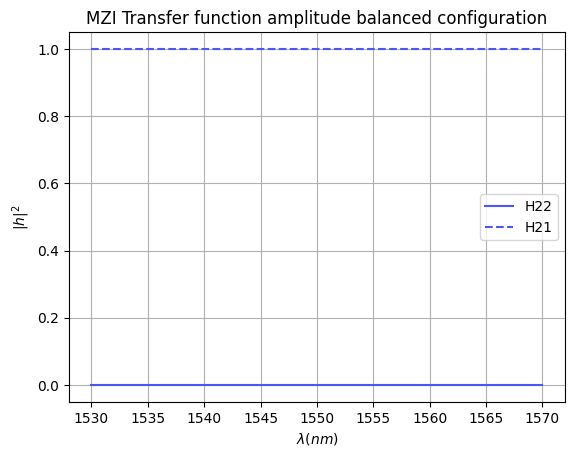

In [31]:
SOI = np.loadtxt('SOI-w450-h220-clad600.txt', skiprows=1, delimiter='\t')

wvl = SOI[:, 0]
neffu = SOI[:, 3] #balanced configuration // (neff TE mode) upper arm
neffd = SOI[:, 3] #balanced configuration // (neff TE mode) under arm

# Parameters arms
alphau = 0
Lu = 5
alphad = 0
Ld = 5

# Parameters couplers
gamma_a = 0
gamma_b = 0
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.5)


H22, H21 = mathematical_MZ(
    wvl, alphau, alphad, # Losses uper and down arm, respectively
    Lu, Ld, # Length upper and down arm, respectively
    neffu, neffd, # Effective indexes of each arm
    gamma_a, gamma_b, # Excess losses of coupler a and b
    K_a, K_b, # coupling constant of each coupler
    title = 'MZI Transfer function amplitude balanced configuration',
    nm = True
)

### Unbalanced

Well, as in 3 and 4 ask us for the usuals unbalanced types let's do here a amplitude imbalance interferometer. For that, we are going to consider two different couplers and two different waveguide lengths

#### Amplitude imbalance

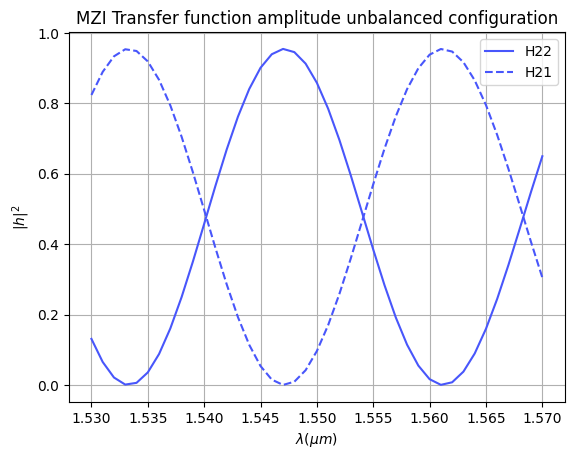

In [77]:
## SOI cross-section ##
SOI = np.loadtxt('SOI-w450-h220-clad600.txt', skiprows=1, delimiter='\t')

wvl = SOI[:, 0]
neffu = SOI[:, 3] #balanced configuration // (neff TE mode) upper arm
neffd = SOI[:, 3] #balanced configuration // (neff TE mode) under arm

# Parameters arms
alphau = 0
Lu = 5
alphad = 0
Ld = 25

# Parameters couplers
gamma_a = 0.0228
gamma_b = 0.0228
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.5)


H22, H21 = mathematical_MZ(
    wvl, alphau, alphad, # Losses uper and down arm, respectively
    Lu, Ld, # Length upper and down arm, respectively
    neffu, neffd, # Effective indexes of each arm
    gamma_a, gamma_b, # Excess losses of coupler a and b
    K_a, K_b, # coupling constant of each coupler
    title = 'MZI Transfer function amplitude unbalanced configuration',
    nm = False
)

In this case. introducing excess loss to one coupler we see hoy the output power decrease, wich is a logical thing. What happens is the two couplers don't have the same K?

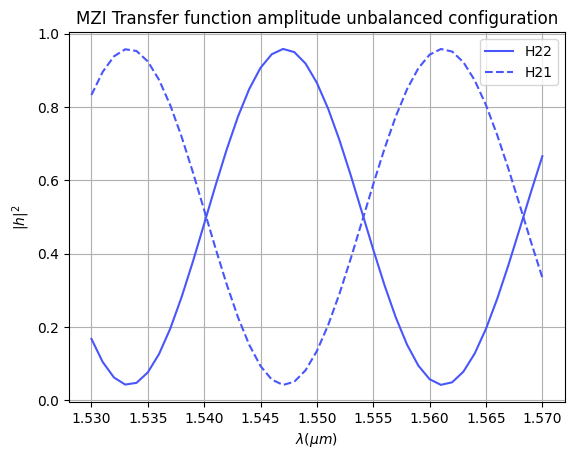

In [96]:
## SOI cross-section ##
SOI = np.loadtxt('SOI-w450-h220-clad600.txt', skiprows=1, delimiter='\t')

wvl = SOI[:, 0]
neffu = SOI[:, 3] #balanced configuration // (neff TE mode) upper arm
neffd = SOI[:, 3] #balanced configuration // (neff TE mode) under arm

# Parameters arms
alphau = 0
Lu = 5
alphad = 0
Ld = 25

# Parameters couplers
gamma_a = 0
gamma_b = 0
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.7)


H22, H21 = mathematical_MZ(
    wvl, alphau, alphad, # Losses uper and down arm, respectively
    Lu, Ld, # Length upper and down arm, respectively
    neffu, neffd, # Effective indexes of each arm
    gamma_a, gamma_b, # Excess losses of coupler a and b
    K_a, K_b, # coupling constant of each coupler
    title = 'MZI Transfer function amplitude unbalanced configuration'
)

We can see that just ass adding excess losses to the couplers, not having a 0.5 K in one coupler reduces the power of the utputs but in a smaller way that adding excess losses (sure this will deppend on the exact values of K and gamma). However, in our design lab of MMi we saw that even thought we can have a not perfect K MMI maybe it has 0.51-0.52 K and for those values the power decrease is minimmal. However, for 0.0228 gamma (a 0.1 dB excess loss) we see a bigger effect of the power loss in the outputs

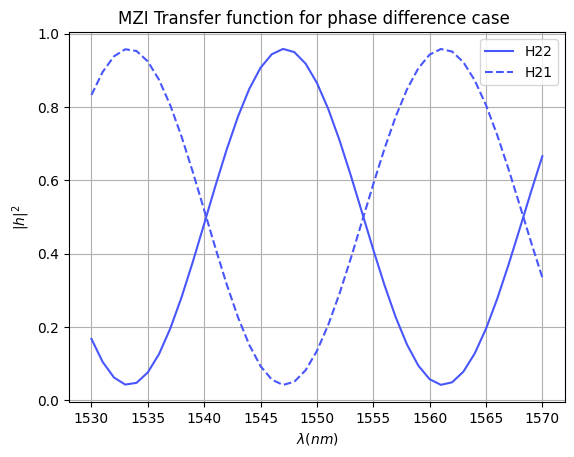

--- H22 ---
  Max amplitude : 0.958078
  Min amplitude : 0.042144
  Mean FSR      : 27.885799 nm
  FSR (troughs) : [27.885799] nm
--- H21 ---
  Max amplitude : 0.957856
  Min amplitude : 0.041922
  Mean FSR      : 27.885799 nm
  FSR (peaks)   : [27.885799] nm


In [86]:

H22, H21, res_H22, res_H21 = evaluate_mzi(
    wvl=wvl,
    alphau=0.0, alphad=0.0,
    Lu=5, Ld=25,          # um (must be Lu != Ld for fringes when neffu == neffd)
    neffu=neffu, neffd=neffd,
    gamma_a=0.0, gamma_b=0.0,
    K_a=0.5, K_b=0.7,
    nm=True,
    title = 'MZI Transfer function for phase difference case ',
    plot_extrema=False
)

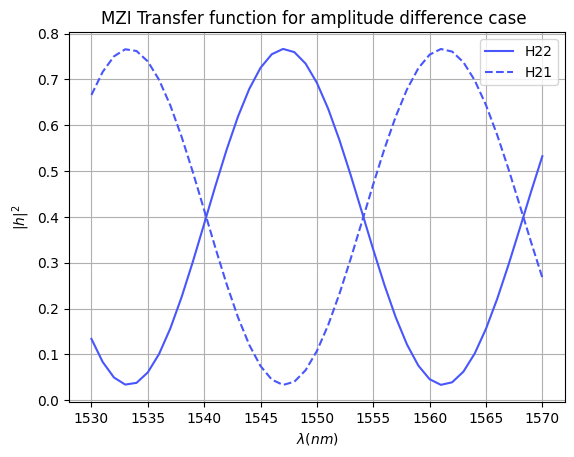

--- H22 ---
  Max amplitude : 0.766462
  Min amplitude : 0.033715
  Mean FSR      : 27.885799 nm
  FSR (troughs) : [27.885799] nm
--- H21 ---
  Max amplitude : 0.766285
  Min amplitude : 0.033538
  Mean FSR      : 27.885799 nm
  FSR (peaks)   : [27.885799] nm


In [90]:
H22, H21, res_H22, res_H21 = evaluate_mzi(
    wvl=wvl,
    alphau=0.0, alphad=0.0,
    Lu=5, Ld=25,          # um (must be Lu != Ld for fringes when neffu == neffd)
    neffu=neffu, neffd=neffd,
    gamma_a=0.0, gamma_b=0.2,
    K_a=0.5, K_b=0.7,
    nm=True,
    title = 'MZI Transfer function for amplitude difference case ',
    plot_extrema=False
)

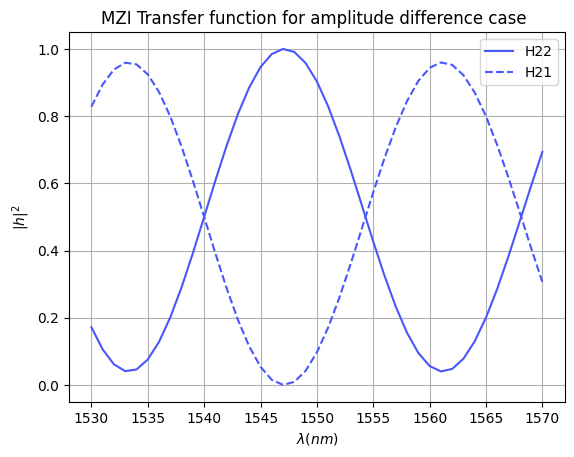

--- H22 ---
  Max amplitude : 0.999812
  Min amplitude : 0.040421
  Mean FSR      : 27.885799 nm
  FSR (troughs) : [27.885799] nm
--- H21 ---
  Max amplitude : 0.959579
  Min amplitude : 0.000188
  Mean FSR      : 27.885799 nm
  FSR (peaks)   : [27.885799] nm


In [91]:
H22, H21, res_H22, res_H21 = evaluate_mzi(
    wvl=wvl,
    alphau=0.0, alphad=0.0,
    Lu=5, Ld=25,          # um (must be Lu != Ld for fringes when neffu == neffd)
    neffu=neffu, neffd=neffd,
    gamma_a=0.0, gamma_b=0,
    K_a=0.6, K_b=0.6,
    nm=True,
    title = 'MZI Transfer function for amplitude difference case ',
    plot_extrema=False
)

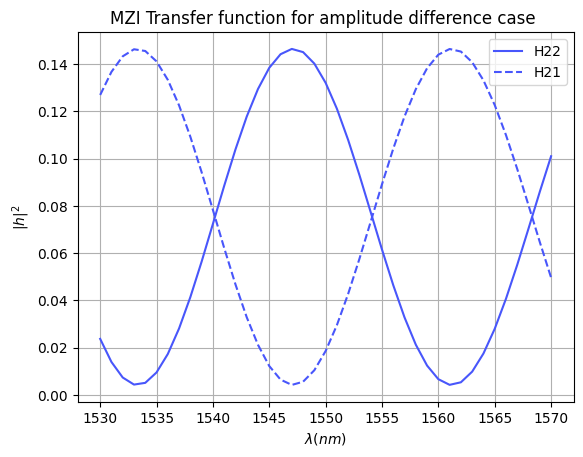

--- H22 ---
  Max amplitude : 0.146419
  Min amplitude : 0.004226
  Mean FSR      : 27.885799 nm
Extintion ratio : 97.11343338325943
  FSR (troughs) : [27.885799] nm
--- H21 ---
  Max amplitude : 0.146384
  Min amplitude : 0.004192
  Mean FSR      : 27.885799 nm
Extintion ratio : 97.13624725536766
  FSR (peaks)   : [27.885799] nm


In [114]:
H22, H21, res_H22, res_H21 = evaluate_mzi(
    wvl=wvl,
    alphau=0, alphad=0.5, #dB/um
    Lu=5, Ld=25,          # um (must be Lu != Ld for fringes when neffu == neffd)
    neffu=neffu, neffd=neffd,
    gamma_a=0.0, gamma_b=0,
    K_a=0.9, K_b=0.5,
    nm=True,
    title = 'MZI Transfer function for amplitude difference case ',
    plot_extrema=False
)

#### Phase difference

For this case, we are gonna select in one arm SiN in cladding as a usual waveguide and in the other one, SiN in water

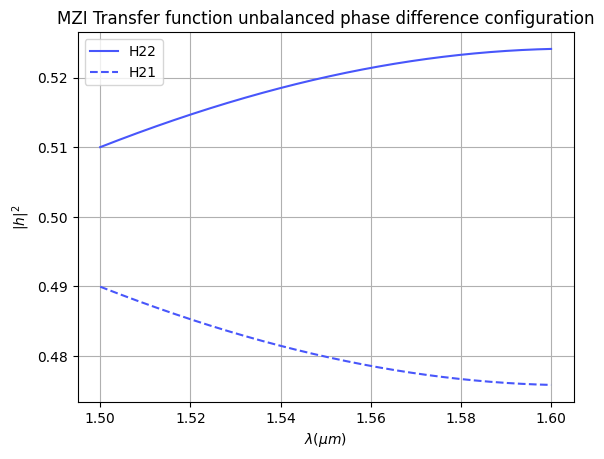

In [ ]:
## SiN cross-section ##
SiN_clad = np.loadtxt('SiN-h300nm-w1000nm-Cladding.txt', skiprows=1, delimiter='\t')
SiN_wat = np.loadtxt('SiN-h300nm-w1000nm-Air.txt', skiprows=1, delimiter='\t')

wvl0 = SiN_clad[:, 0]
neffu0 = SiN_clad[:, 3] #balanced configuration // (neff TE mode)
neffd0 = SiN_wat[:, 3] #balanced configuration // (neff TE mode)

interp_neffu = interp1d(wvl0, neffu0, kind='cubic')  # Cubic interpolation for smoothness
interp_neffd = interp1d(wvl0, neffd0, kind='cubic')
wvl = np.linspace(wvl0.min(), wvl0.max(), 1000)
neffu = interp_neffu(wvl)
neffd = interp_neffd(wvl)

# Parameters arms
alphau = 0
Lu = 5
alphad = 0
Ld = 5

# Parameters couplers
gamma_a = 0
gamma_b = 0
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.5)


H22, H21 = mathematical_MZ(
    wvl, alphau, alphad, # Losses uper and down arm, respectively
    Lu, Ld, # Length upper and down arm, respectively
    neffu, neffd, # Effective indexes of each arm
    gamma_a, gamma_b, # Excess losses of coupler a and b
    K_a, K_b, # coupling constant of each coupler
    title = 'MZI Transfer function unbalanced phase difference configuration'
)

So the phase difference induced by the difference of index is so small that even we can see the interferometric patter, the extintion rate of the outputs is to small (being extintion rate the deep of the dip). How can we amplify this effect? Doing a fuly unbalanced arm,i.e., also introducing phase delay thakns to a difference of the length of the arms

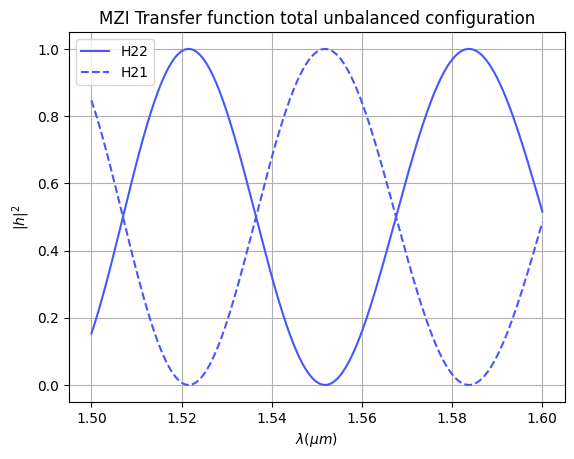

In [ ]:
## SiN cross-section ##
SiN_clad = np.loadtxt('SiN-h300nm-w1000nm-Cladding.txt', skiprows=1, delimiter='\t')
SiN_wat = np.loadtxt('SiN-h300nm-w1000nm-Air.txt', skiprows=1, delimiter='\t')

wvl0 = SiN_clad[:, 0]
neffu0 = SiN_clad[:, 3] #balanced configuration // (neff TE mode)
neffd0 = SiN_wat[:, 3] #balanced configuration // (neff TE mode)

interp_neffu = interp1d(wvl0, neffu0, kind='cubic')  # Cubic interpolation for smoothness
interp_neffd = interp1d(wvl0, neffd0, kind='cubic')
wvl = np.linspace(wvl0.min(), wvl0.max(), 1000)
neffu = interp_neffu(wvl)
neffd = interp_neffd(wvl)



# Parameters arms
alphau = 0
Lu = 25
alphad = 0
Ld = 25

# Parameters couplers
gamma_a = 0
gamma_b = 0
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.5)


H22, H21 = mathematical_MZ(
    wvl, alphau, alphad, # Losses uper and down arm, respectively
    Lu, Ld, # Length upper and down arm, respectively
    neffu, neffd, # Effective indexes of each arm
    gamma_a, gamma_b, # Excess losses of coupler a and b
    K_a, K_b, # coupling constant of each coupler
    title = 'MZI Transfer function total unbalanced configuration'
)

And yeah, now we can see how the effect have been amplified. Also, note that changing the difference of effective index between the waveguides the spectrum of the device shifted in wavelength! 

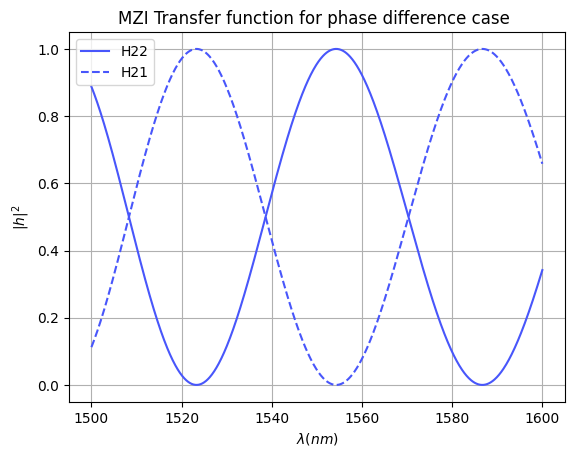

--- H22 ---
  Max amplitude : 0.999998
  Min amplitude : 0.000000
  Mean FSR      : 63.394184 nm
  FSR (troughs) : [63.394184] nm
--- H21 ---
  Max amplitude : 1.000000
  Min amplitude : 0.000002
  Mean FSR      : 63.394184 nm
  FSR (peaks)   : [63.394184] nm


In [46]:
## SiN cross-section ##
SiN_clad = np.loadtxt('SiN-h300nm-w1000nm-Cladding.txt', skiprows=1, delimiter='\t')
SiN_wat = np.loadtxt('SiN-h300nm-w1000nm-Air.txt', skiprows=1, delimiter='\t')

wvl0 = SiN_clad[:, 0]
neffu0 = SiN_clad[:, 3] #balanced configuration // (neff TE mode)
neffd0 = SiN_wat[:, 3] #balanced configuration // (neff TE mode)

interp_neffu = interp1d(wvl0, neffu0, kind='cubic')  # Cubic interpolation for smoothness
interp_neffd = interp1d(wvl0, neffd0, kind='cubic')
wvl = np.linspace(wvl0.min(), wvl0.max(), 1000)
neffu = interp_neffu(wvl)
neffd = interp_neffd(wvl)


H22, H21, res_H22, res_H21 = evaluate_mzi(
    wvl=wvl,
    alphau=0.0, alphad=0.0,
    Lu=25, Ld=5,          # um (must be Lu != Ld for fringes when neffu == neffd)
    neffu=neffu, neffd=neffd,
    gamma_a=0.0, gamma_b=0.0,
    K_a=0.5, K_b=0.5,
    nm=True,
    title = 'MZI Transfer function for phase difference case ',
    plot_extrema=False
)

In [55]:
SiN_clad = np.loadtxt('SiN-h300nm-w1000nm-Cladding.txt', skiprows=1, delimiter='\t')
SiN_wat = np.loadtxt('SiN-h300nm-w1000nm-Air.txt', skiprows=1, delimiter='\t')

wvl0 = SiN_clad[:, 0]
neffu0 = SiN_clad[:, 3] #balanced configuration // (neff TE mode)
neffd0 = SiN_wat[:, 3] #balanced configuration // (neff TE mode)

interp_neffu = interp1d(wvl0, neffu0, kind='cubic')  # Cubic interpolation for smoothness
interp_neffd = interp1d(wvl0, neffd0, kind='cubic')
wvl = np.linspace(wvl0.min(), wvl0.max(), 1000)
neffu = interp_neffu(wvl)
neffd = interp_neffd(wvl)
lambda_0 = 1.55
nm = 1000

n_g_clad = neffu - wvl*(np.gradient(neffu)/np.gradient(wvl))
n_g_wat = neffd - wvl*(np.gradient(neffd)/np.gradient(wvl))
idx = np.abs(wvl - lambda_0).argmin()
FSR = np.abs(lambda_0**2/(Ld*n_g_wat[idx]-Lu*n_g_clad[idx]))
Lu = 5
Ld = 25
FSR = np.abs(lambda_0**2/(Ld*n_g_wat[idx]-Lu*n_g_clad[idx]))
print(f'FSR = {FSR*1000} nm for Lu = {Lu} and Ld = {Ld}' )
Lu  =25
Ld = 5
FSR = np.abs(lambda_0**2/(Ld*n_g_wat[idx]-Lu*n_g_clad[idx]))
print(f'FSR = {FSR*1000} nm for Lu = {Lu} and Ld = {Ld}' )

FSR = 61.89577722871262 nm for Lu = 5 and Ld = 25
FSR = 62.974118538579134 nm for Lu = 25 and Ld = 5


#### Phase delay

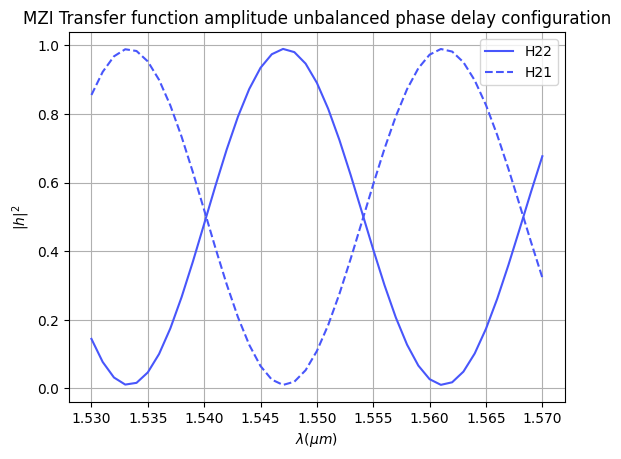

In [60]:
## SOI cross-section ##
SOI = np.loadtxt('SOI-w450-h220-clad600.txt', skiprows=1, delimiter='\t')

wvl = SOI[:, 0]
neffu = SOI[:, 3] #balanced configuration // (neff TE mode) upper arm
neffd = SOI[:, 3] #balanced configuration // (neff TE mode) under arm

# Parameters arms
alphau = 0
Lu = 5
alphad = 0
Ld = 25

# Parameters couplers
gamma_a = 0
gamma_b = 0
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.6)


H22, H21 = mathematical_MZ(
    wvl, alphau, alphad, # Losses uper and down arm, respectively
    Lu, Ld, # Length upper and down arm, respectively
    neffu, neffu, # Effective indexes of each arm
    gamma_a, gamma_b, # Excess losses of coupler a and b
    K_a, K_b, # coupling constant of each coupler
    title = 'MZI Transfer function amplitude unbalanced phase delay configuration'
)

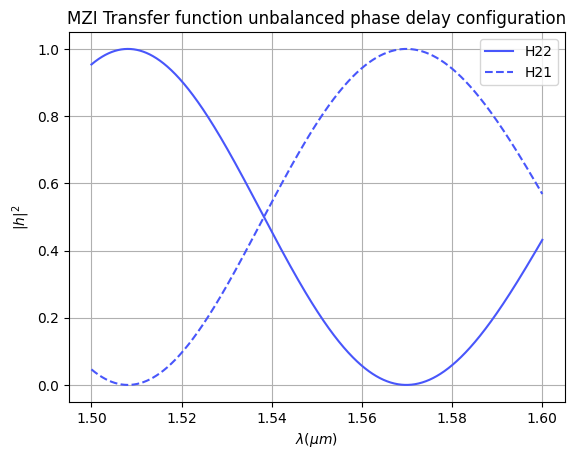

In [62]:
## SiN cross-section ##
SiN_clad = np.loadtxt('SiN-h300nm-w1000nm-Cladding.txt', skiprows=1, delimiter='\t')
SiN_wat = np.loadtxt('SiN-h300nm-w1000nm-Air.txt', skiprows=1, delimiter='\t')

wvl0 = SiN_clad[:, 0]
neffu0 = SiN_clad[:, 3] #balanced configuration // (neff TE mode)
neffd0 = SiN_wat[:, 3] #balanced configuration // (neff TE mode)

interp_neffu = interp1d(wvl0, neffu0, kind='cubic')  # Cubic interpolation for smoothness
interp_neffd = interp1d(wvl0, neffd0, kind='cubic')
wvl = np.linspace(wvl0.min(), wvl0.max(), 1000)
neffu = interp_neffu(wvl)
neffd = interp_neffd(wvl)



# Parameters arms
alphau = 0
Lu = 5
alphad = 0
Ld = 15

# Parameters couplers
gamma_a = 0
gamma_b = 0
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.5)


H22, H21 = mathematical_MZ(
    wvl, alphau, alphad, # Losses uper and down arm, respectively
    Lu, Ld, # Length upper and down arm, respectively
    neffu, neffu, # Effective indexes of each arm
    gamma_a, gamma_b, # Excess losses of coupler a and b
    K_a, K_b, # coupling constant of each coupler
    title = 'MZI Transfer function unbalanced phase delay configuration'
)

What we see? Changing the path difference between arms changes the space between resonence, i.e., the free spectral range

# **Assesment 2.** Taking into account the n_{eff} values for the SOI cross-section, what would be the path difference ($\Delta L$ = $L_u$ - $L_d$) needed to obtain a Free Spectral Range of 40 nm? Introduce the obtained value in the model to check the MZI response. Hint: We assume 1550 nm as the central design wavelength ($\lambda _0$=1550 nm).

We know from theory classes that the FSR is equal to $\frac{\lambda^2}{n_g (\lambda) \Delta L}$. To compute the group index of SOI technology we can do $n_g (\lambda)  = \bar{n} - \lambda \frac{\partial \bar{n}(\lambda)}{\partial \lambda}$

In [9]:
## SOI cross-section ##
SOI = np.loadtxt('SOI-w450-h220-clad600.txt', skiprows=1, delimiter='\t')
lambda_0 = 1.55
nm = 1000
wvl = SOI[:, 0]
neffu = SOI[:, 3] #balanced configuration // (neff TE mode) upper arm
neffd = SOI[:, 3] #balanced configuration // (neff TE mode) under arm

n_g = neffu - wvl*(np.gradient(neffu)/np.gradient(wvl))
idx = np.abs(wvl - lambda_0).argmin()
print(f'Group index of SOI for {lambda_0} nm is {n_g[20]}')
n_g_1550 = n_g[idx]


Group index of SOI for 1.55 nm is 4.293269999999957


In [10]:
FSR = 40 #nm
DeltaL = (lambda_0*nm)**2/(n_g_1550*FSR)
print(f'The path difference needed for a FSR of {FSR} nm is {DeltaL/1000} um')

The path difference needed for a FSR of 40 nm is 13.989919105949685 um


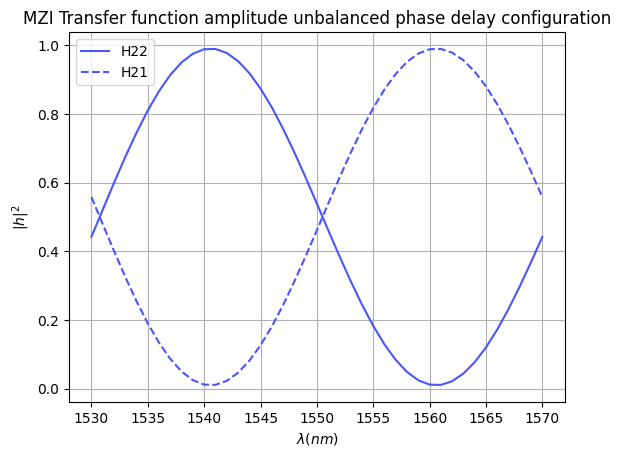

In [34]:
# Parameters arms
alphau = 0
Lu = 5
alphad = 0
Ld = 5 + DeltaL/1000

# Parameters couplers
gamma_a = 0
gamma_b = 0
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.6)


H22, H21 = mathematical_MZ(
    wvl, alphau, alphad, # Losses uper and down arm, respectively
    Lu, Ld, # Length upper and down arm, respectively
    neffu, neffd, # Effective indexes of each arm
    gamma_a, gamma_b, # Excess losses of coupler a and b
    K_a, K_b, # coupling constant of each coupler
    title = 'MZI Transfer function amplitude unbalanced phase delay configuration',
    nm = True
)

It seems that yes, we have a FSR of 40 nm but is out of our window, let's induce a phase difference in one arm to shift the spectrum and see the FSR

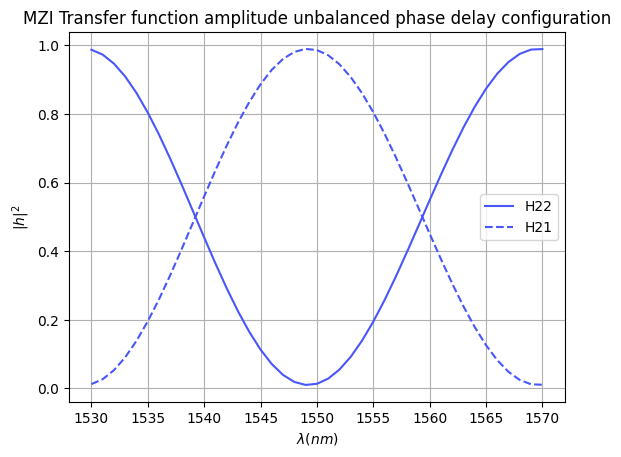

In [11]:
# Parameters arms
alphau = 0
Lu = 5
alphad = 0
Ld = 5 + DeltaL/1000

# Parameters couplers
gamma_a = 0
gamma_b = 0
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.6)


H22, H21 = mathematical_MZ(
    wvl, alphau, alphad, # Losses uper and down arm, respectively
    Lu, Ld, # Length upper and down arm, respectively
    neffu, neffd-0.023, # Effective indexes of each arm
    gamma_a, gamma_b, # Excess losses of coupler a and b
    K_a, K_b, # coupling constant of each coupler
    title = 'MZI Transfer function amplitude unbalanced phase delay configuration',
    nm = True
)

And here we go, we can see the distance of approximately 40 nm between the two maximun (or minima) values

## 2. MZI simulation implemented with SAX
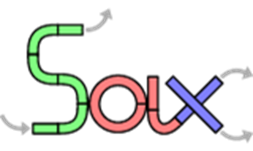

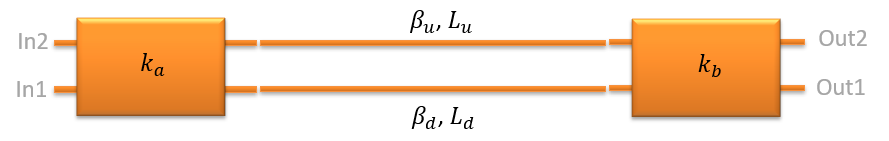


### 2.1 Components S matrix


In [3]:
# Waveguide Model

def waveguide(wl=1.55, neff=1.6072, length=10.0, loss=0.0) -> sax.SDict:
    phase = 2 * jnp.pi * neff * length / wl
    transmission = 10 ** (-loss * length / 20) * jnp.exp(1j * phase) # loss(dB/um)
    wg_dict = sax.reciprocal(
        {
            ("in0", "out0"): transmission,
        }
    )
    return wg_dict


# Coupler Model (an easy one)

def coupler(coupling=0.5) -> sax.SDict:
    kappa = coupling**0.5
    tau = (1 - coupling) ** 0.5
    coupler_dict = sax.reciprocal(
        {
            ("in0", "out0"): tau,
            ("in0", "out1"): kappa * np.exp(-1j * np.pi / 2.0),
            ("in1", "out0"): kappa * np.exp(-1j * np.pi / 2.0), # Al acoplar se gana una fase de pi/2
            ("in1", "out1"): tau,
        }
    )
    return coupler_dict

### 2.2 MZI SAX Circuit Model

In [4]:
# MZI

mzi, info = sax.circuit(
    netlist={
        "instances": {
            "coup_a": "coupler",
            "wvg_u": "waveguide",
            "wvg_d": "waveguide",
            "coup_b": "coupler",
        },
        "connections": {
            "coup_a,out0": "wvg_d,in0",
            "wvg_d,out0": "coup_b,in0",
            "coup_a,out1": "wvg_u,in0",
            "wvg_u,out0": "coup_b,in1",
        },
        "ports": {
            "in0": "coup_a,in0",
            "in1": "coup_a,in1",
            "out0": "coup_b,out0",
            "out1": "coup_b,out1",
        },
    },
    models={
        "coupler": coupler,
        "waveguide": waveguide,
    },
)


### 2.3. MZI Modeling
**Assesment 3**: Now, we are going to implement the design parameters in the MZI model developed in SAX and compare the response obtained with that simulated by mathematical formulation.

This will help us to identify any error in the definition of the SAX model single components.

In order to implement the SAX model, take as example the following lines:

    mzi_test = mzi(wl=wl,
                coup_a = ...
                wvg_d={"length": l_d, "neff": ...},
                wvg_u={"length": l_u, "neff": ...},
                coup_b = ... )

    H00 = mzi_test["in0", "out0"]

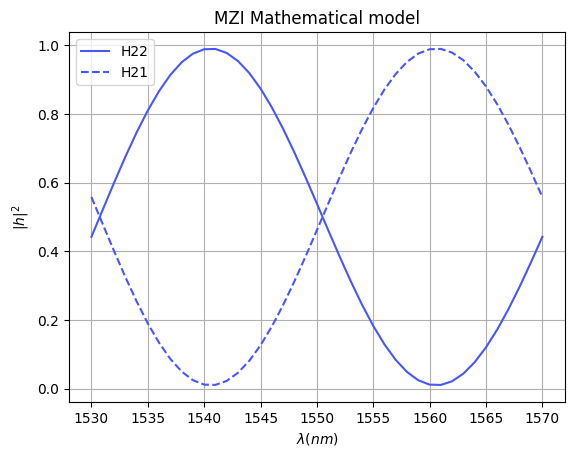

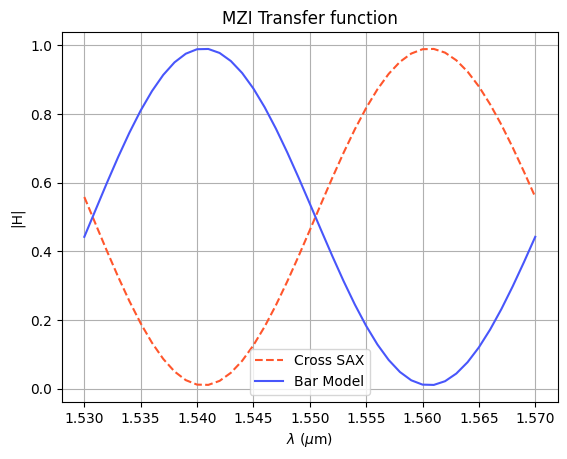

In [12]:
mzi_test = mzi(wl=wvl,
            coup_a={"coupling":K_a},
            wvg_u={"wl":wvl, "neff":neffu, "length": Lu, "loss":alphau},
            wvg_d={"wl":wvl, "neff":neffd, "length": Ld, "loss":alphad},
            coup_b={"coupling":K_b},
            )

h00 = mzi_test["in0", "out0"]
h01 = mzi_test["in0", "out1"]
h11 = mzi_test["in1", "out1"]
h10 = mzi_test["in1", "out0"]

# Mathematical MZI
H22, H21 = mathematical_MZ(
    wvl, alphau, alphad, # Losses uper and down arm, respectively
    Lu, Ld, # Length upper and down arm, respectively
    neffu, neffd, # Effective indexes of each arm
    gamma_a, gamma_b, # Excess losses of coupler a and b
    K_a, K_b, # coupling constant of each coupler
    title = 'MZI Mathematical model',
    nm = True
)

# Plot
color = cm.rainbow(np.linspace(0, 1, 10))
plt.figure()
#plt.plot(wvl, np.abs(h11)**2, linestyle="-", color=color[8], label=f"Bar SAX")
plt.plot(wvl, np.abs(h10)**2, linestyle="--", color=color[8], label=f"Cross SAX")
plt.plot(wvl,H22, linestyle="-", color=color[1], label=f"Bar Model")
#plt.plot(wvl,H21, linestyle="--", color=color[1], label=f"Cross Model")
# Values of the mathematical mode
#plt.plot(wvl, H22, linestyle='-', color=color[1], label='H22')
#plt.plot(wvl, H21, linestyle='--', color=color[1], label='H21')
plt.xlabel(r'$\lambda$ ($\mu$m)')
plt.ylabel('|H|')
plt.legend()
plt.title('MZI Transfer function')
plt.grid(True)
plt.show()

# **Assessment 4.** Designing an MZI for filtering at a specific wavelength. Calculate and adjust the arm lengths to configure the MZI to have a maximum transmission at 1550 nm.

In [2]:
## SOI cross-section ##
SOI = np.loadtxt('SOI-w450-h220-clad600.txt', skiprows=1, delimiter='\t')
lambda_0 = 1.55
nm = 1000
wvl = SOI[:, 0]
neffu = SOI[:, 3] #balanced configuration // (neff TE mode) upper arm
neffd = SOI[:, 3] #balanced configuration // (neff TE mode) under arm
idx = np.abs(wvl-lambda_0).argmin()
neffu_1550 = neffu[idx]

# To have maximun in a lambda, the phase difference must be 2pi, considering equal material arms
DeltaL = lambda_0/neffu_1550
print(f'The length difference to have a maximun for {lambda_0*1000} nm is {DeltaL} um ')

The length difference to have a maximun for 1550.0 nm is 0.6579589688297245 um 


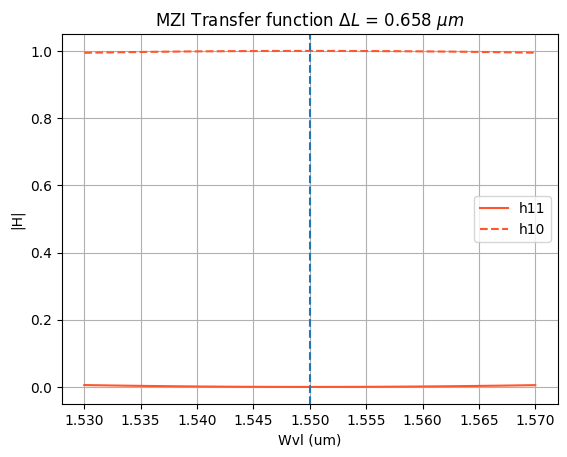

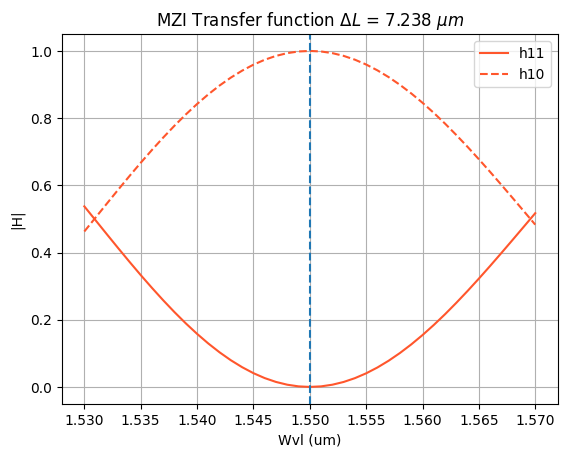

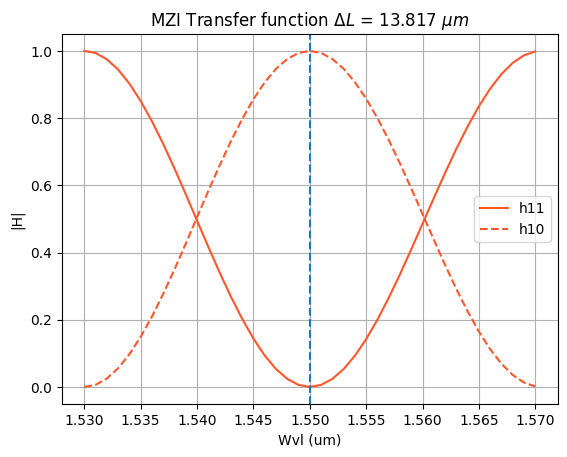

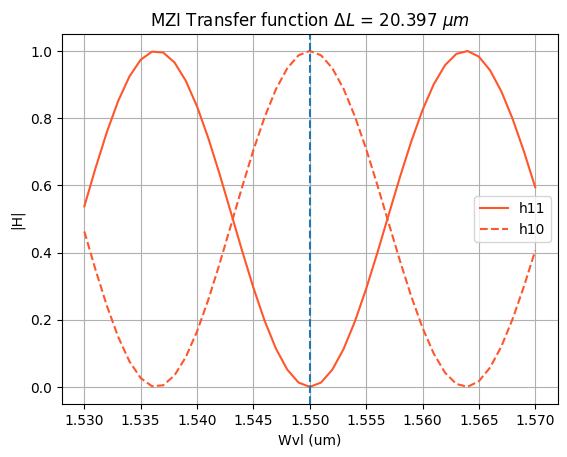

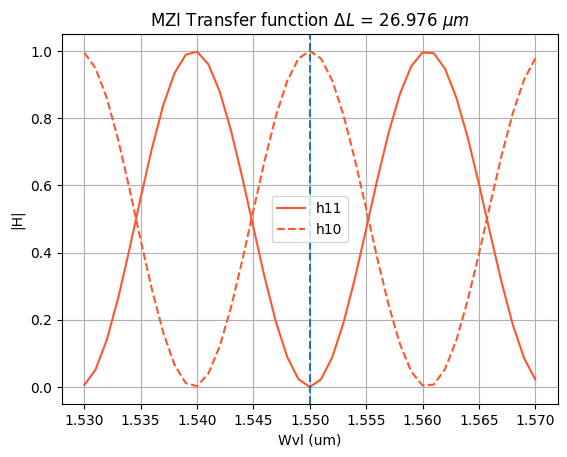

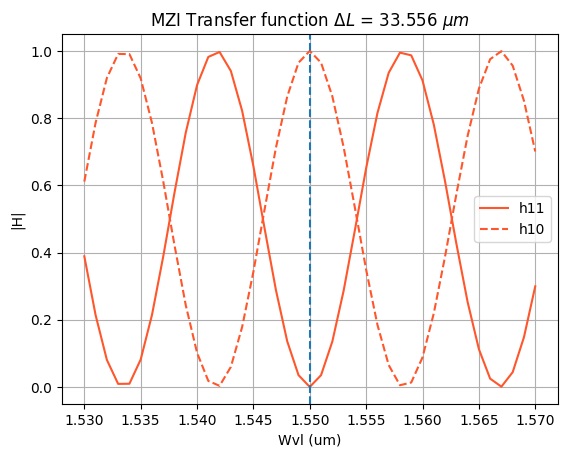

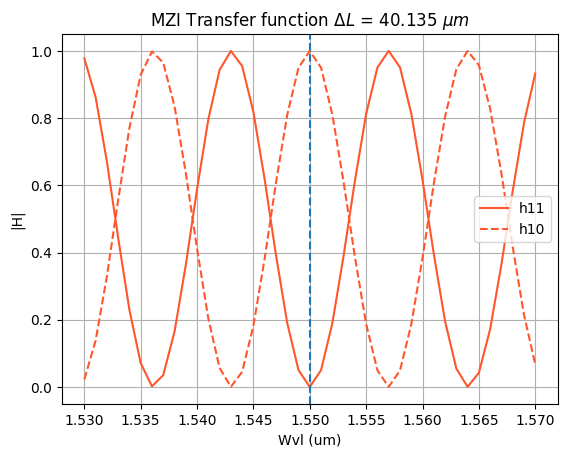

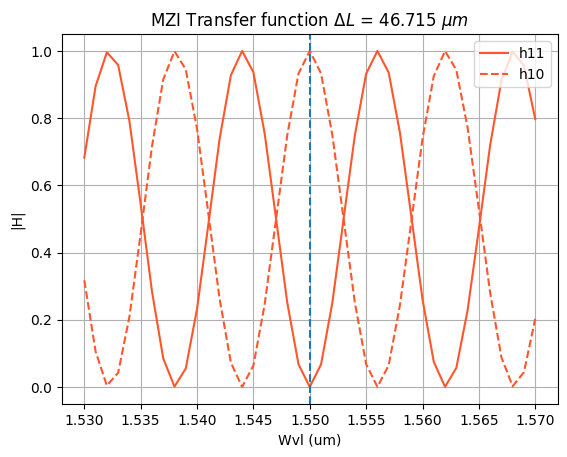

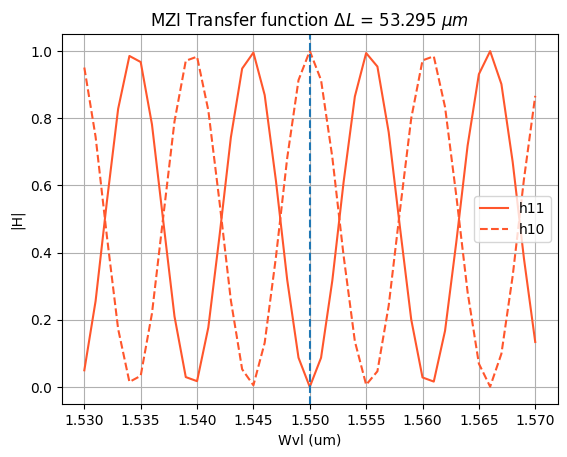

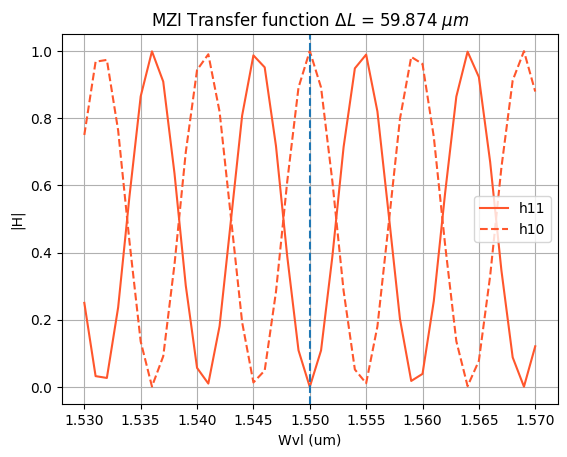

In [13]:
# Coupling
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.5)
Lu = 5
alphau = 0
alphad = 0

for m in np.arange(0,100,10):
    DeltaL = (1+m)*(lambda_0/neffu_1550)
    Ld = Lu + DeltaL
    mzi_test = mzi(wl=wvl,
                coup_a={"coupling":K_a},
                wvg_u={"wl":wvl, "neff":neffu, "length": Lu, "loss":alphau},
                wvg_d={"wl":wvl, "neff":neffd, "length": Ld, "loss":alphad},
                coup_b={"coupling":K_b},
                )

    h00 = mzi_test["in0", "out0"]
    h01 = mzi_test["in0", "out1"]
    h11 = mzi_test["in1", "out1"]
    h10 = mzi_test["in1", "out0"]


    # Plot
    color = cm.rainbow(np.linspace(0, 1, 10))
    plt.figure()
    plt.plot(wvl, np.abs(h11)**2, linestyle="-", color=color[8], label=f"h11")
    plt.plot(wvl, np.abs(h10)**2, linestyle="--", color=color[8], label=f"h10")
    plt.axvline(1.55, linestyle = '--' )
    # Values of the mathematical mode
    #plt.plot(wvl, H22, linestyle='-', color=color[1], label='H22')
    #plt.plot(wvl, H21, linestyle='--', color=color[1], label='H21')
    plt.xlabel('Wvl (um)')
    plt.ylabel('|H|')
    plt.title(f'MZI Transfer function {r'$\Delta L$'} = {round(DeltaL,3)} {r'$\mu m$'}')
    plt.grid(True)
    plt.legend()
    plt.show()

# **Assessment 5.** Let's see how the response of the MZI variates with the effective index. Vary the effective index of one of the arms and analyze how the spectrum shifts. To do this, you can use the data provided in the .txt files entitled ‘SiN’.
Can you give an example of an application where this configuration is used?


In [174]:
## SiN cross-section ##
SiN_clad = np.loadtxt('SiN-h300nm-w1000nm-Cladding.txt', skiprows=1, delimiter='\t')
SiN_wat = np.loadtxt('SiN-h300nm-w1000nm-Water.txt', skiprows=1, delimiter='\t')

wvl0 = SiN_clad[:, 0]
neffu0 = SiN_clad[:, 3] #balanced configuration // (neff TE mode)
neffd0 = SiN_wat[:, 3] #balanced configuration // (neff TE mode)

interp_neffu = interp1d(wvl0, neffu0, kind='cubic')  # Cubic interpolation for smoothness
interp_neffd = interp1d(wvl0, neffd0, kind='cubic')
wvl = np.linspace(wvl0.min(), wvl0.max(), 1000)
neffu = interp_neffu(wvl)
neffd = interp_neffd(wvl)

In [185]:
## SiN cross-section ##
#Im gonna fix Lu to 5 microns and then search the Ld to have maximuns at 1.55 microns
Lu = 5
lambda_0 = 1.55
idx = np.abs(wvl-lambda_0).argmin()
neffu_1550 = neffu[idx]
neffd_1550 = neffd[idx]
Ld_list = []
for m in np.linspace(10,100,10):
    # To avoid negative L, I use +m, cos is pair, it doesn't matter +m or -m
    Ld_list.append(((neffu_1550*Lu)+m*lambda_0)/neffd_1550)

In [186]:
print(Ld_list)

[np.float64(15.155287216465553), np.float64(25.206628424949177), np.float64(35.2579696334328), np.float64(45.30931084191643), np.float64(55.360652050400056), np.float64(65.41199325888368), np.float64(75.4633344673673), np.float64(85.51467567585091), np.float64(95.56601688433454), np.float64(105.61735809281817)]


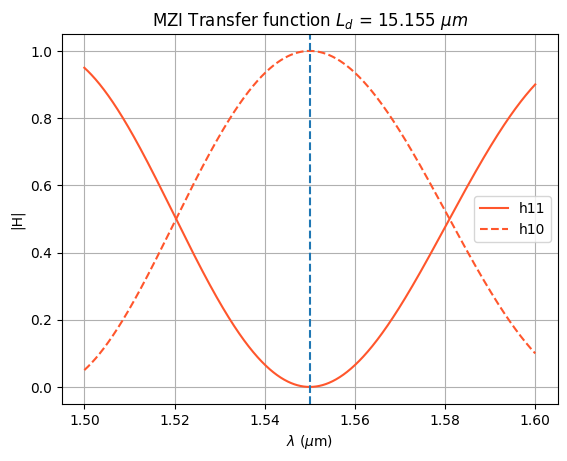

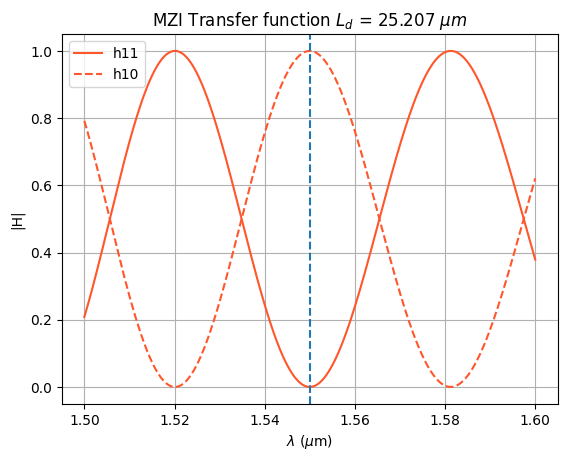

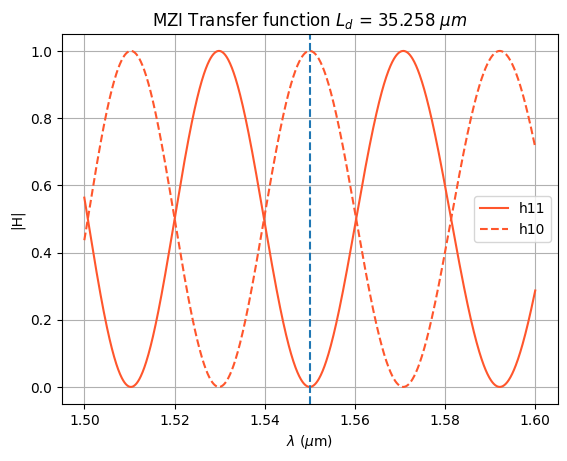

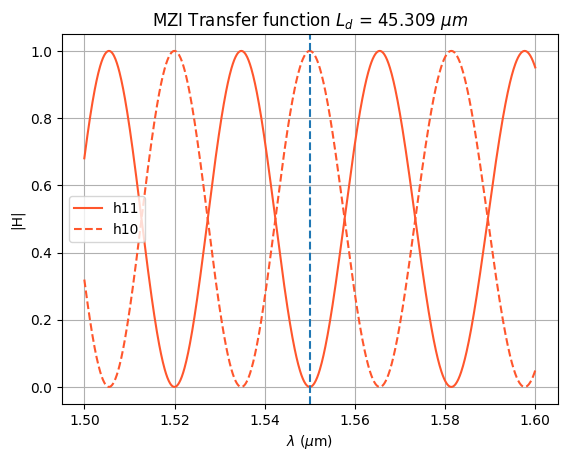

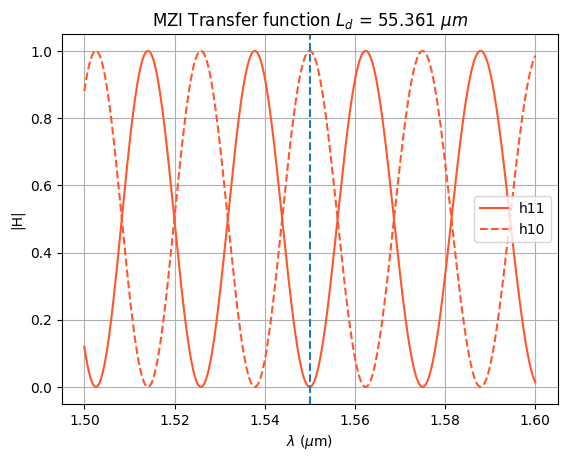

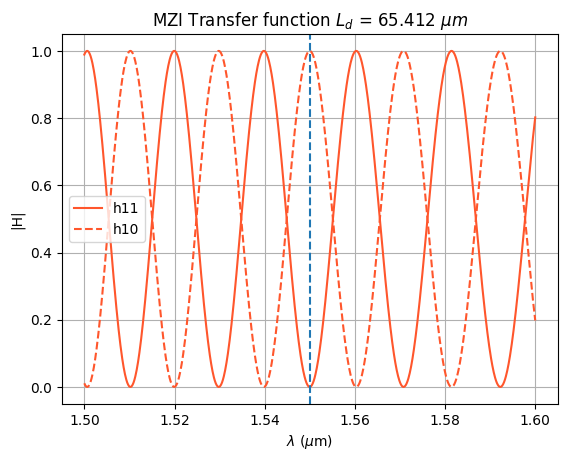

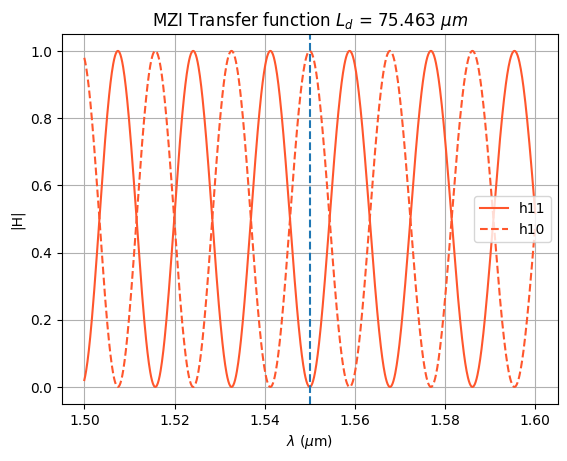

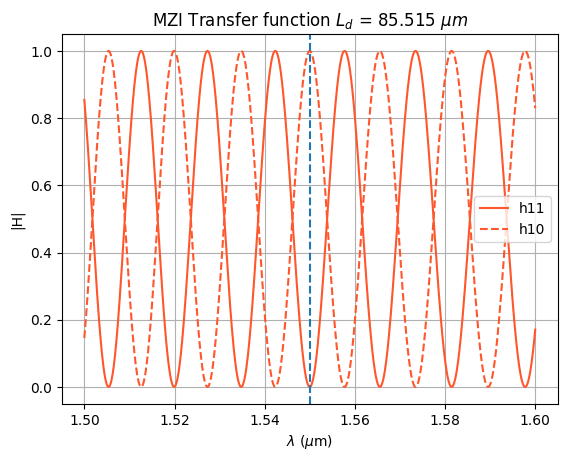

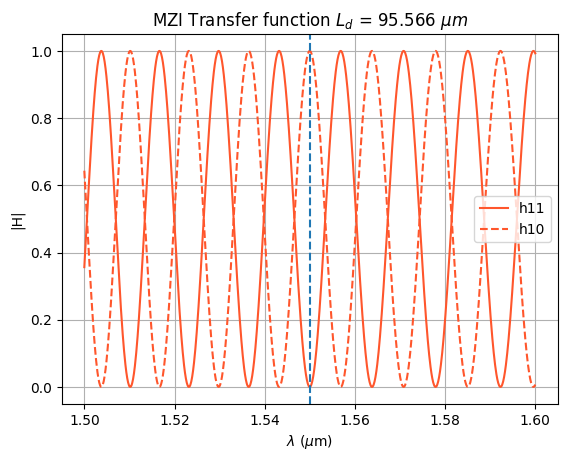

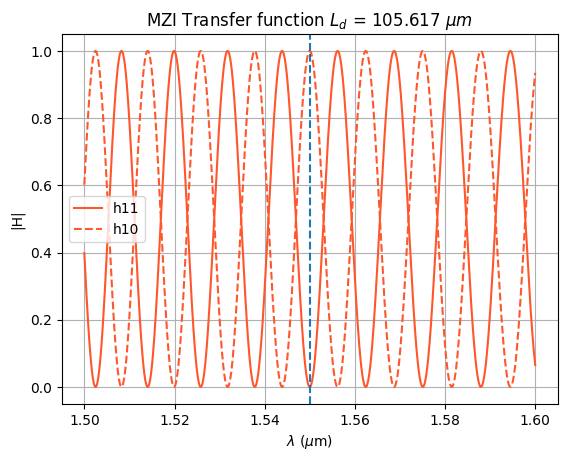

In [ ]:
# Coupling
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.6)
Lu = 5
alphau = 0
alphad = 0

for Ld in Ld_list:
    mzi_test = mzi(wl=wvl,
                coup_a={"coupling":K_a},
                wvg_u={"wl":wvl, "neff":neffu, "length": Lu, "loss":alphau},
                wvg_d={"wl":wvl, "neff":neffd, "length": Ld, "loss":alphad},
                coup_b={"coupling":K_b},
                )

    h00 = mzi_test["in0", "out0"]
    h01 = mzi_test["in0", "out1"]
    h11 = mzi_test["in1", "out1"]
    h10 = mzi_test["in1", "out0"]


    # Plot
    color = cm.rainbow(np.linspace(0, 1, 10))
    plt.figure()
    plt.plot(wvl, np.abs(h11)**2, linestyle="-", color=color[8], label=f"h11")
    plt.plot(wvl, np.abs(h10)**2, linestyle="--", color=color[8], label=f"h10")
    plt.axvline(1.55, linestyle = '--' )
    # Values of the mathematical mode
    #plt.plot(wvl, H22, linestyle='-', color=color[1], label='H22')
    #plt.plot(wvl, H21, linestyle='--', color=color[1], label='H21')
    plt.xlabel(r'$\lambda$ ($\mu$m)')
    plt.ylabel('|H|')
    plt.title(f'MZI Transfer function {r'$L_d$'} = {round(Ld,3)} {r'$\mu m$'}')
    plt.grid(True)
    plt.legend()
    plt.show()

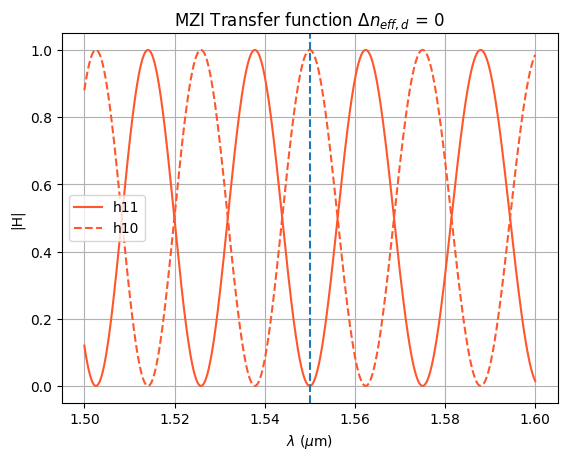

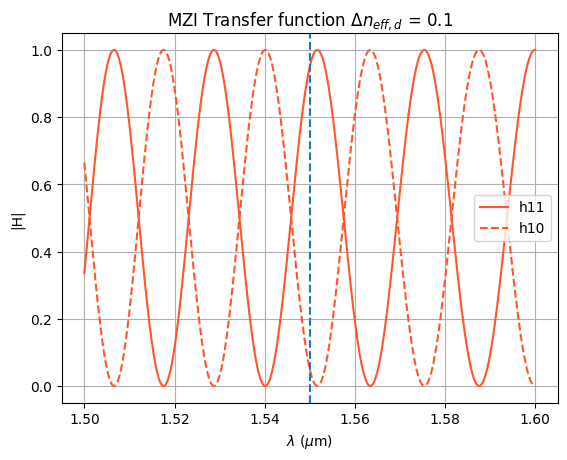

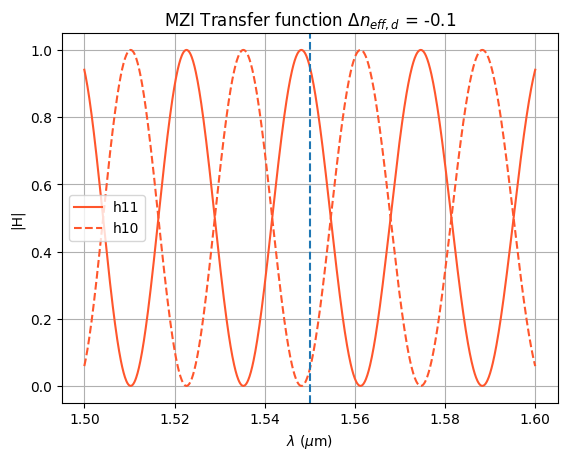

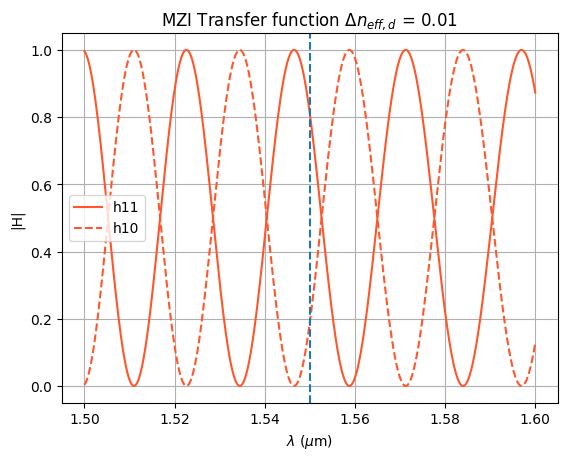

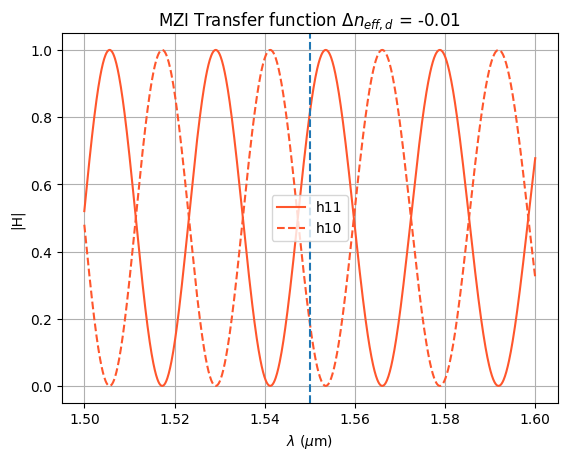

In [ ]:
# Coupling
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.6)
Lu = 5
Ld = 55.361
alphau = 0
alphad = 0
Delta_neff_d = [0, 0.1,-0.1,0.01,-0.01]
for Deltan in Delta_neff_d:
    mzi_test = mzi(wl=wvl,
                coup_a={"coupling":K_a},
                wvg_u={"wl":wvl, "neff":neffu, "length": Lu, "loss":alphau},
                wvg_d={"wl":wvl, "neff":neffd+Deltan, "length": Ld, "loss":alphad},
                coup_b={"coupling":K_b},
                )

    h00 = mzi_test["in0", "out0"]
    h01 = mzi_test["in0", "out1"]
    h11 = mzi_test["in1", "out1"]
    h10 = mzi_test["in1", "out0"]


    # Plot
    color = cm.rainbow(np.linspace(0, 1, 10))
    plt.figure()
    plt.plot(wvl, np.abs(h11)**2, linestyle="-", color=color[8], label=f"h11")
    plt.plot(wvl, np.abs(h10)**2, linestyle="--", color=color[8], label=f"h10")
    plt.axvline(1.55, linestyle = '--' )
    # Values of the mathematical mode
    #plt.plot(wvl, H22, linestyle='-', color=color[1], label='H22')
    #plt.plot(wvl, H21, linestyle='--', color=color[1], label='H21')
    plt.xlabel(r'$\lambda$ ($\mu$m)')
    plt.ylabel('|H|')
    plt.title(f'MZI Transfer function {r'$\Delta n_{eff,d}$'} = {Deltan}')
    plt.grid(True)
    plt.legend()
    plt.show()

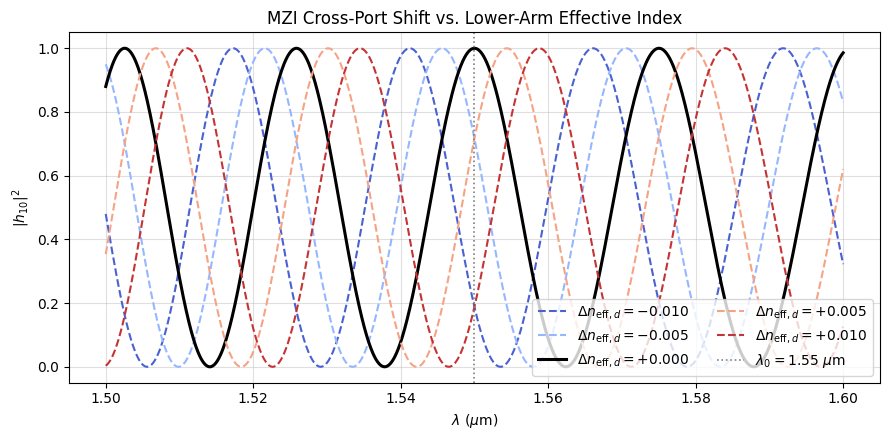

In [195]:
K_a, K_b = 0.5, 0.5
Lu, Ld = 5.0, 55.361
alphau, alphad = 0.0, 0.0

Delta_neff_d = [-0.01, -0.005, 0.0, 0.005, 0.01]  # sub-FSR steps first, son variaciones de neff que no hacen que pasen más de un máximo por 1550nm, si pasa más de uno no sabré qué se ha movido

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = cm.coolwarm(np.linspace(0.05, 0.95, len(Delta_neff_d)))

for Deltan, col in zip(Delta_neff_d, colors):
    mzi_test = mzi(
        wl=wvl,
        coup_a={"coupling": K_a},
        wvg_u={"wl": wvl, "neff": neffu, "length": Lu, "loss": alphau},
        wvg_d={"wl": wvl, "neff": neffd + Deltan, "length": Ld, "loss": alphad},
        coup_b={"coupling": K_b},
    )
    H10 = np.abs(mzi_test["in1", "out0"]) ** 2

    is_ref = np.isclose(Deltan, 0.0)
    ax.plot(
        wvl, H10,
        color="black" if is_ref else col,
        linewidth=2.2 if is_ref else 1.5,
        linestyle="-" if is_ref else "--",
        label=rf"$\Delta n_{{\mathrm{{eff}},d}} = {Deltan:+.3f}$",
    )

ax.axvline(1.55, color="gray", linestyle=":", linewidth=1.2, label=r"$\lambda_0 = 1.55\ \mu\mathrm{m}$")
#ax.set_xlim(max(wvl.min(), 1.51), min(wvl.max(), 1.59))  # zoom to ~3 FSRs around 1.55 um
ax.set_xlabel(r"$\lambda\ (\mu\mathrm{m})$")
ax.set_ylabel(r"$|h_{10}|^2$")
ax.set_title("MZI Cross-Port Shift vs. Lower-Arm Effective Index")
ax.grid(True, alpha=0.4)
ax.legend(ncol=2, loc="lower right")
plt.tight_layout()
plt.show()

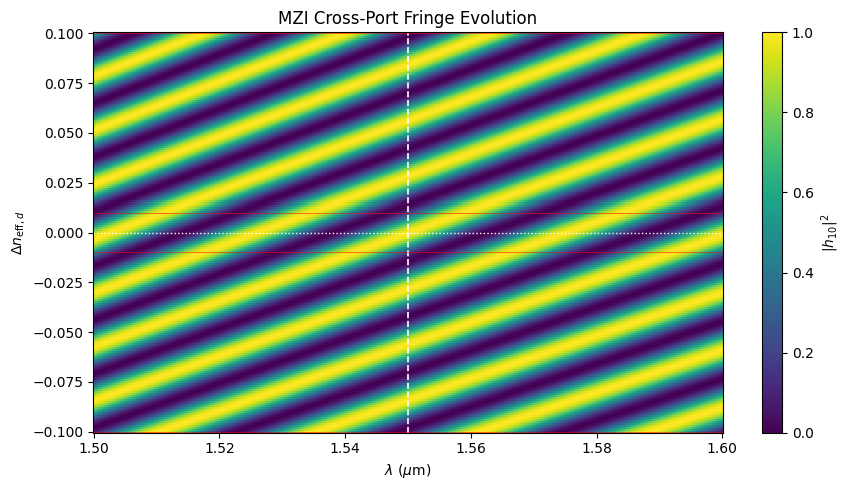

In [194]:
Delta_neff_sweep = np.linspace(-0.1, 0.1, 200)
H10_map = np.empty((len(Delta_neff_sweep), len(wvl)))

for i, Deltan in enumerate(Delta_neff_sweep):
    mzi_test = mzi(
        wl=wvl,
        coup_a={"coupling": K_a},
        wvg_u={"wl": wvl, "neff": neffu, "length": Lu, "loss": alphau},
        wvg_d={"wl": wvl, "neff": neffd + Deltan, "length": Ld, "loss": alphad},
        coup_b={"coupling": K_b},
    )
    H10_map[i] = np.abs(mzi_test["in1", "out0"]) ** 2

fig, ax = plt.subplots(figsize=(9, 5))
pcm = ax.pcolormesh(wvl, Delta_neff_sweep, H10_map, shading="auto", cmap="viridis")
fig.colorbar(pcm, ax=ax, label=r"$|h_{10}|^2$")

# Crosshair at the design peak (1.55 um, Delta n = 0)
ax.axvline(1.55, color="white", linestyle="--", linewidth=1.2)
ax.axhline(0.0, color="white", linestyle=":", linewidth=1.0)

# Mark the specific discrete points you wanted to inspect
for dn in [-0.1, -0.01, 0.01, 0.1]:
    ax.axhline(dn, color="red", linestyle="-", linewidth=0.6, alpha=0.6)

ax.set_xlabel(r"$\lambda\ (\mu\mathrm{m})$")
ax.set_ylabel(r"$\Delta n_{\mathrm{eff},d}$")
ax.set_title("MZI Cross-Port Fringe Evolution")
plt.tight_layout()
plt.show()

# **Assessment 6.** Explore how cascading two MZIs affects the transmission spectrum. To do so, design a system in which two MZIs are cascaded. Simulate and observe the spectrum, explaining how the transmission peaks behave.

In [14]:
# Waveguide Model

def waveguide(wl=1.55, neff=1.6072, length=10.0, loss=0.0) -> sax.SDict:
    phase = 2 * jnp.pi * neff * length / wl
    transmission = 10 ** (-loss * length / 20) * jnp.exp(1j * phase) # loss(dB/um)
    wg_dict = sax.reciprocal(
        {
            ("in0", "out0"): transmission,
        }
    )
    return wg_dict


# Coupler Model (an easy one)

def coupler(coupling=0.5) -> sax.SDict:
    kappa = coupling**0.5
    tau = (1 - coupling) ** 0.5
    coupler_dict = sax.reciprocal(
        {
            ("in0", "out0"): tau,
            ("in0", "out1"): kappa * np.exp(-1j * np.pi / 2.0),
            ("in1", "out0"): kappa * np.exp(-1j * np.pi / 2.0), # Al acoplar se gana una fase de pi/2
            ("in1", "out1"): tau,
        }
    )
    return coupler_dict

In [53]:
mzi, info = sax.circuit(
    netlist={
        "instances": {
            "coup_a": "coupler",
            "wvg_u": "waveguide",
            "wvg_d": "waveguide",
            "coup_b": "coupler",
        },
        "connections": {
            "coup_a,out0": "wvg_d,in0",
            "wvg_d,out0": "coup_b,in0",
            "coup_a,out1": "wvg_u,in0",
            "wvg_u,out0": "coup_b,in1",
        },
        "ports": {
            "in0": "coup_a,in0",
            "in1": "coup_a,in1",
            "out0": "coup_b,out0",
            "out1": "coup_b,out1",
        },
    },
    models={
        "coupler": coupler,
        "waveguide": waveguide,
    },
)

In [ ]:
# I define the concatenation of two mzi from the single mzi model above and I add waveguides between them
two_mzi_waveguides, info = sax.circuit(
    netlist={
        "instances":{
            "mzi_1":"mzi", "mzi_2":"mzi","wvg_u":"waveguide","wvg_d":"waveguide",
        },
        "connections":{
            "mzi_1,out0":"wvg_d,in0",
            "wvg_d,out0":"mzi_2,in0",
            "mzi_1,out1":"wvg_u,in0",
            "wvg_u,out0":"mzi_2,in1",
        },
        "ports":{
            "in0":"mzi_1,in0",
            "in1":"mzi_1,in1",
            "out0":"mzi_2,out0",
            "out1":"mzi_2,out1",
        },
    },
    models={"mzi":mzi, "waveguide":waveguide
    },
)

In [16]:
# I define the concatenation of two mzi from the single mzi model above
two_mzi, info = sax.circuit(
    netlist={
        "instances":{
            "mzi_1":"mzi", "mzi_2":"mzi",
        },
        "connections":{
            "mzi_1,out0":"mzi_2,in0",
            "mzi_1,out1":"mzi_2,in1",
        },
        "ports":{
            "in0":"mzi_1,in0",
            "in1":"mzi_1,in1",
            "out0":"mzi_2,out0",
            "out1":"mzi_2,out1",
        },
    },
    models={"mzi":mzi,
    },
)

In [183]:
## SiN cross-section ##
SiN_clad = np.loadtxt('SiN-h300nm-w1000nm-Cladding.txt', skiprows=1, delimiter='\t')
SiN_wat = np.loadtxt('SiN-h300nm-w1000nm-Water.txt', skiprows=1, delimiter='\t')

wvl0 = SiN_clad[:, 0]
neffu0 = SiN_clad[:, 3] #balanced configuration // (neff TE mode)
neffd0 = SiN_wat[:, 3] #balanced configuration // (neff TE mode)

interp_neffu = interp1d(wvl0, neffu0, kind='cubic')  # Cubic interpolation for smoothness
interp_neffd = interp1d(wvl0, neffd0, kind='cubic')

# Coupling
wvl = np.linspace(wvl0.min(), wvl0.max(), 1000)
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.5)
K_c = np.full(wvl.shape, 0.5)
K_d = np.full(wvl.shape, 0.5)
Lu = 5
Ld = 25
alphau = 0.0
alphad = 0.0

neffu = interp_neffu(wvl)
neffd = interp_neffd(wvl)

T = two_mzi(
    wl = wvl,
    mzi_1 = {"coup_a":{"coupling":K_a},"wvg_u":{"wl":wvl, "neff":neffu, "length": 5, "loss":alphau},
             "wvg_d":{"wl":wvl, "neff":neffu, "length": 25, "loss":alphad},"coup_b":{"coupling":K_b}},
    mzi_2 = {"coup_a":{"coupling":K_c},"wvg_u":{"wl":wvl, "neff":neffu, "length": 20, "loss":alphau},
             "wvg_d":{"wl":wvl, "neff":neffu, "length": 60, "loss":alphad},"coup_b":{"coupling":K_d}}
)
T2 = two_mzi_waveguides(
    wl = wvl,
    mzi_1 = {"coup_a":{"coupling":K_a},"wvg_u":{"wl":wvl, "neff":neffu, "length": 5, "loss":alphau},
             "wvg_d":{"wl":wvl, "neff":neffu, "length": 25, "loss":alphad},"coup_b":{"coupling":K_b}},
    mzi_2 = {"coup_a":{"coupling":K_c},"wvg_u":{"wl":wvl, "neff":neffu, "length": 20, "loss":alphau},
             "wvg_d":{"wl":wvl, "neff":neffu, "length": 60, "loss":alphad},"coup_b":{"coupling":K_d}},
    wvg_u = {"wl":wvl, "neff":neffu, "length": 5, "loss":alphau},
    wvg_d = {"wl":wvl, "neff":neffu, "length": 5, "loss":alphau},
)
h00_2 = T["in0", "out0"]
h01_2 = T["in0", "out1"]
h11_2 = T["in1", "out1"]
h10_2 = T["in1", "out0"]

h00_22 = T2["in0", "out0"]
h01_22= T2["in0", "out1"]
h11_22 = T2["in1", "out1"]
h10_22 = T2["in1", "out0"]

In [184]:
mzi_test = mzi(wl = wvl, coup_a={"coupling":K_a},wvg_u={"wl":wvl,"neff":neffu, "length": 40, "loss":alphau},wvg_d={"wl":wvl, "neff":neffu, "length": 20, "loss":alphad},
coup_b={"coupling":K_b},
            )

h00 = mzi_test["in0", "out0"]
h01 = mzi_test["in0", "out1"]
h11 = mzi_test["in1", "out1"]
h10 = mzi_test["in1", "out0"]

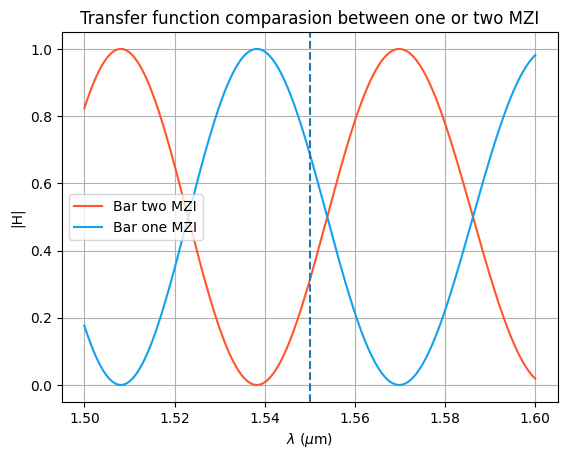

In [185]:
color = cm.rainbow(np.linspace(0, 1, 10))
plt.figure()
plt.plot(wvl, np.abs(h11_2)**2, linestyle="-", color=color[8], label=f"Bar two MZI")
#plt.plot(wvl, np.abs(h10_2)**2, linestyle="--", color=color[8], label=f"Cross two MZI")
plt.plot(wvl, np.abs(h11)**2, linestyle="-", color=color[2], label=f"Bar one MZI")
#plt.plot(wvl, np.abs(h10)**2, linestyle="--", color=color[2], label=f"Cross one MZI")
plt.axvline(1.55, linestyle = '--' )
# Values of the mathematical mode
#plt.plot(wvl, H22, linestyle='-', color=color[1], label='H22')
#plt.plot(wvl, H21, linestyle='--', color=color[1], label='H21')
plt.xlabel(r'$\lambda$ ($\mu$m)')
plt.ylabel('|H|')
plt.title(f'Transfer function comparasion between one or two MZI')
plt.grid(True)
plt.legend()
plt.show()

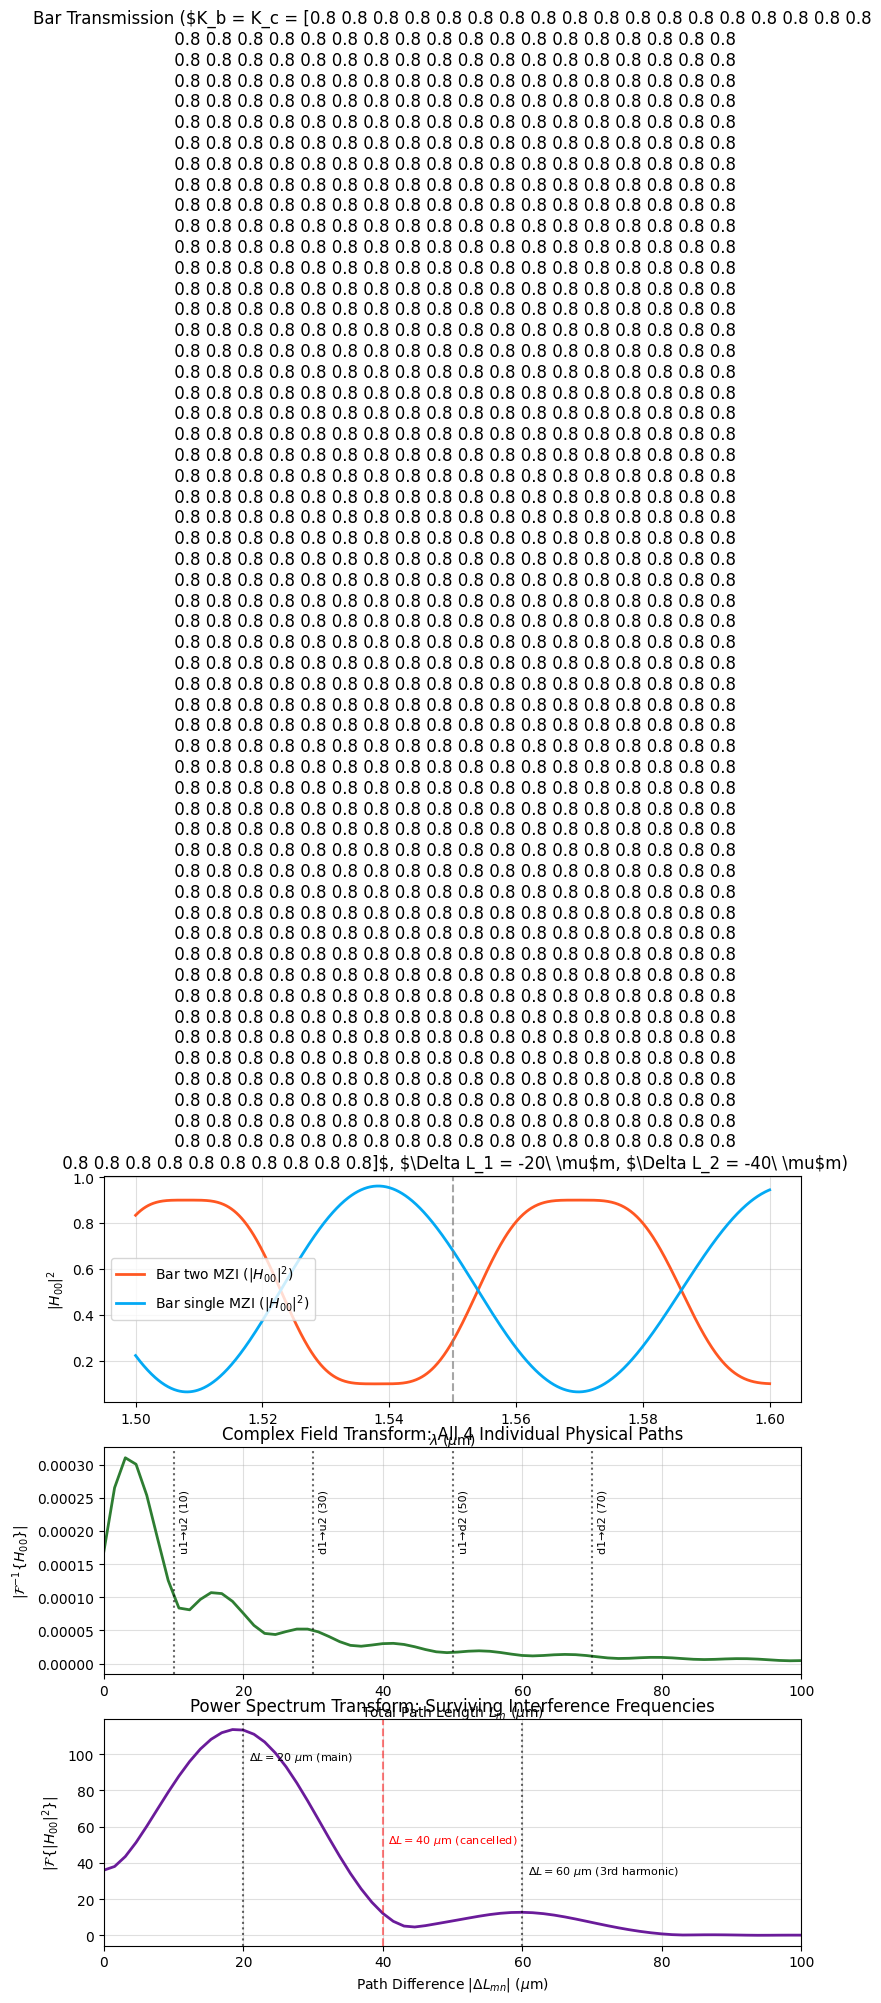

In [178]:
# ==========================================
# 4. Fourier Analysis (Optical Frequency Domain)
# ==========================================
wvl0 = 1.55
c = 299792458.0  # m/s
nu = c / (wvl * 1e-6)  # Hz (descending because wvl is ascending)
nu_uni = np.linspace(nu.min(), nu.max(), len(nu))
dnu = nu_uni[1] - nu_uni[0]

h00_2 = h11_2
P_bar_2 = np.abs(h11_2)**2
np.abs(h10_2)**2
# Interpolate onto uniform frequency grid
H_uni = np.interp(nu_uni, nu[::-1], h00_2[::-1])
P_uni = np.interp(nu_uni, nu[::-1], P_bar_2[::-1])

window = np.hanning(len(nu_uni))
n_fft = 8 * len(nu_uni)  # zero-padding for smooth peak interpolation

# A) IFFT of complex field H -> reveals all 4 individual paths L_m
ng = 1.95
impulse_H = np.abs(np.fft.ifft(H_uni * window, n=n_fft))
tau_H = np.fft.fftfreq(n_fft, d=dnu)
L_um = (tau_H * c / ng) * 1e6
pos_mask = L_um >= 0

# B) RFFT of power |H|^2 -> reveals surviving pairwise path differences dL_mn
spec_P = np.abs(np.fft.rfft((P_uni - P_uni.mean()) * window, n=n_fft))
tau_P = np.fft.rfftfreq(n_fft, d=dnu)
dL_um = (tau_P * c / ng) * 1e6

# ==========================================
# 5. Visualization
# ==========================================
fig, axes = plt.subplots(3, 1, figsize=(9, 10))

# Panel 1: Transmission spectra
axes[0].plot(wvl, P_bar_2, color="#ff5722", lw=2, label="Bar two MZI ($|H_{00}|^2$)")
axes[0].plot(wvl, np.abs(h11)**2, color="#03a9f4", lw=2, label="Bar single MZI ($|H_{00}|^2$)")
axes[0].axvline(wvl0, ls="--", color="gray", alpha=0.7)
axes[0].set_xlabel(r"$\lambda$ ($\mu$m)")
axes[0].set_ylabel(r"$|H_{00}|^2$")
axes[0].set_title(rf"Bar Transmission ($K_b = K_c = {K_b}$, $\Delta L_1 = -20\ \mu$m, $\Delta L_2 = -40\ \mu$m)")
axes[0].legend()
axes[0].grid(True, alpha=0.4)

# Panel 2: Complex field FFT (individual optical paths)
axes[1].plot(L_um[pos_mask], impulse_H[pos_mask], color="#2e7d32", lw=2)
for path_len, lbl in [(10, "u1→u2 (10)"), (30, "d1→u2 (30)"), (50, "u1→d2 (50)"), (70, "d1→d2 (70)")]:
    axes[1].axvline(path_len, ls=":", color="black", alpha=0.6)
    axes[1].text(path_len + 0.8, impulse_H[pos_mask].max() * 0.85, lbl, fontsize=8, rotation=90, va="top")
axes[1].set_xlim(0, 100)
axes[1].set_xlabel(r"Total Path Length $L_m$ ($\mu$m)")
axes[1].set_ylabel(r"$|\mathcal{F}^{-1}\{H_{00}\}|$")
axes[1].set_title("Complex Field Transform: All 4 Individual Physical Paths")
axes[1].grid(True, alpha=0.4)

# Panel 3: Power spectrum FFT (surviving interference frequencies)
axes[2].plot(dL_um, spec_P, color="#6a1b9a", lw=2)
axes[2].axvline(20, ls=":", color="black", alpha=0.6)
axes[2].axvline(40, ls="--", color="red", alpha=0.5)
axes[2].axvline(60, ls=":", color="black", alpha=0.6)
axes[2].text(20.8, spec_P.max() * 0.85, r"$\Delta L = 20\ \mu$m (main)", fontsize=8)
axes[2].text(40.8, spec_P.max() * 0.45, r"$\Delta L = 40\ \mu$m (cancelled)", fontsize=8, color="red")
axes[2].text(60.8, spec_P.max() * 0.30, r"$\Delta L = 60\ \mu$m (3rd harmonic)", fontsize=8)
axes[2].set_xlim(0, 100)
axes[2].set_xlabel(r"Path Difference $|\Delta L_{mn}|$ ($\mu$m)")
axes[2].set_ylabel(r"$|\mathcal{F}\{|H_{00}|^2\}|$")
axes[2].set_title("Power Spectrum Transform: Surviving Interference Frequencies")
axes[2].grid(True, alpha=0.4)

plt.show()